In [1]:
# 环境、全局参数、绘图设置（与 learn/0.ipynb 同款）
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

def find_root():
    """notebook 可能在项目根（run_ipynb.py 默认）或 learn/ 下运行，向上找阶段 1 文档。"""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / '阶段1-信号与噪声模型假设.md').is_file():
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

# ---- 阶段 1 初设参数（来自 阶段1-信号与噪声模型假设.md §四，逐行待导师替换）----
GAMMA_NT   = 1.0                    # 默认幅值 1 nT（范围 0.1–10 nT）
F_GRID     = (0.1, 1.0, 10.0)       # 信号频率三点（Hz），覆盖低噪声窗口两端
F_MAIN     = 1.0                    # 演示用主频（Hz）
THETA_DEG  = 40.0                   # 初相（°），未知量，这里仅用于造数据
FS         = 1000.0                 # 仿真采样率（Hz）
T_OBS      = 300.0                  # 观测时长（s），与阈值扫描档对齐
B_BAND     = 10.0                   # 带限带宽（Hz），窄带口径用
ALPHAS     = (0.5, 1.0, 1.2, 1.5)   # 1/f^alpha 四档，与 Sun 等仿真对齐
SEED       = 20261123
_START = time.time()

print(f'ROOT = {ROOT}')
print(f'采样率 {FS:.0f} Hz | 时长 {T_OBS:.0f} s | 样本数 {int(T_OBS * FS)} | '
      f'频点 {F_GRID} Hz | 默认幅值 {GAMMA_NT} nT')

ROOT = C:\Users\22902\WorkBuddy\毕设
采样率 1000 Hz | 时长 300 s | 样本数 300000 | 频点 (0.1, 1.0, 10.0) Hz | 默认幅值 1.0 nT


# 阶段一

## 1. 信号模型：已知频率、未知幅相

$$s(t)=\gamma\cos(\omega t+\theta),\qquad t\in[0,T],\quad \omega=2\pi f$$

- **$\omega$ 先验给定（或给定频段后粗估）**：这是与 D1 两派的根本区别——target-based 要已知偶极子航迹波形，noise-based 不预设波形；本课题只预设「单频周期」这一条结构信息。
- **$\gamma$、$\theta$ 未知待估**：初相位盲区是后面做阵列的直接动机（阶段 3 的事，本号不展开）。
- **频段锚点三处，口径不同不可混用**：频域电磁法 mHz–kHz / pT–μT（说明跨度大，**不用来定参数**）；磁通门低噪声窗口 1–100 Hz、约 1 pT/√Hz（定前端）；本课题初设 0.1–10 Hz、0.1–10 nT（**待导师确认**）。

> 「极低频」在本课题不是 ITU 的 3–30 Hz，也不是 E3 的 mHz–kHz 全段，而是「前端能覆盖、算法能变尺度」的交集。频段不定，SNR 数字就没有意义。

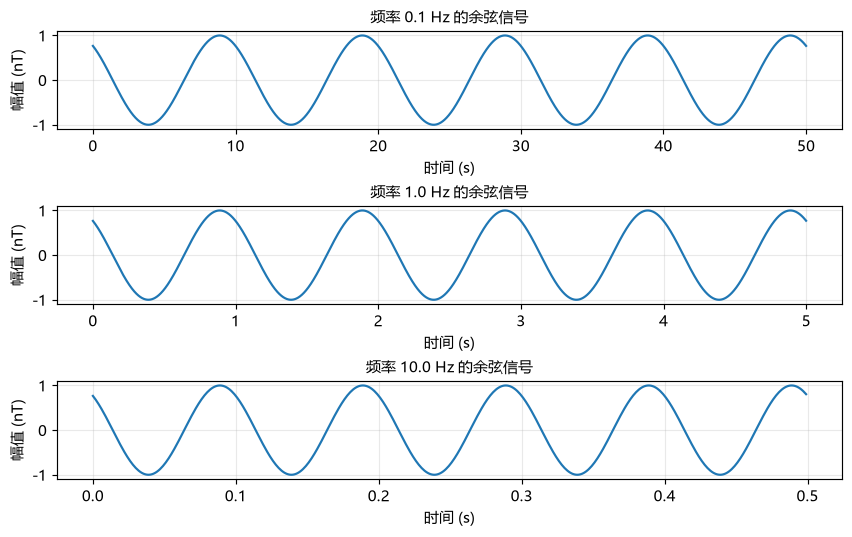

信号均方理论值 γ²/2 = 0.5000 nT²；样本均方 = 0.5000 nT²
目前只有 γ、θ 的「真值」用于造数据；检测时二者都是未知量，见阶段 4–5。


In [2]:
t = np.arange(0, T_OBS, 1.0/FS)
theta = np.deg2rad(THETA_DEG)

fig, axes = plt.subplots(3, 1, figsize=(8, 5), constrained_layout=True)
for ax,f in zip(axes, F_GRID):
    s = GAMMA_NT * np.cos(2*np.pi*f*t + theta)
    win = t < min(T_OBS, 5.0/f)  # 只画前 5 秒，避免图像过长
    ax.plot(t[win], s[win], label=f'{f} Hz')
    ax.set_title(f'频率 {f} Hz 的余弦信号', fontsize=10)
    ax.set_xlabel('时间 (s)')
    ax.set_ylabel('幅值 (nT)')
plt.show()
s_main = GAMMA_NT * np.cos(2*np.pi*F_MAIN*t + theta)
print(f'信号均方理论值 γ²/2 = {GAMMA_NT**2/2:.4f} nT²；样本均方 = {np.mean(s_main**2):.4f} nT²')
print(f'目前只有 γ、θ 的「真值」用于造数据；检测时二者都是未知量，见阶段 4–5。')

## 2. 噪声模型：两档可切换 + 一档待替换

**A 档｜高斯白噪（基线）**：$n\sim\mathcal N(0,\sigma^2)$，每样本独立。与教科书结论对齐，给后续阈值扫描提供干净对照；缺点是会高估算法性能——真实极低频背景不是白的。

**B 档｜$1/f^{\alpha}$ 色噪（主力）**：$S_n(f)\propto f^{-\alpha},\ 0<\alpha<2$，取 0.5 / 1.0 / 1.2 / 1.5 四档（与 ★[3] 仿真设置对齐，便于将来同条件对照）。用频域整形生成：白噪 FFT → 乘 $f^{-\alpha/2}$ → IFFT，**固定随机种子**以便复现；低于 0.03 Hz 的分量置零（300 s 记录本来也分辨不了），否则极低频会独占全部方差。

**C 档｜实测替换（暂缺）**：导师组实测噪声序列到位后，直接当 $H_0$ 样本源。这是把「仿真论文」变成「结合科研」的唯一途径。

> 50 Hz 工频及谐波、脉冲干扰、量化噪声：先留接口，不加。加之前先问「它会不会改变结论」。

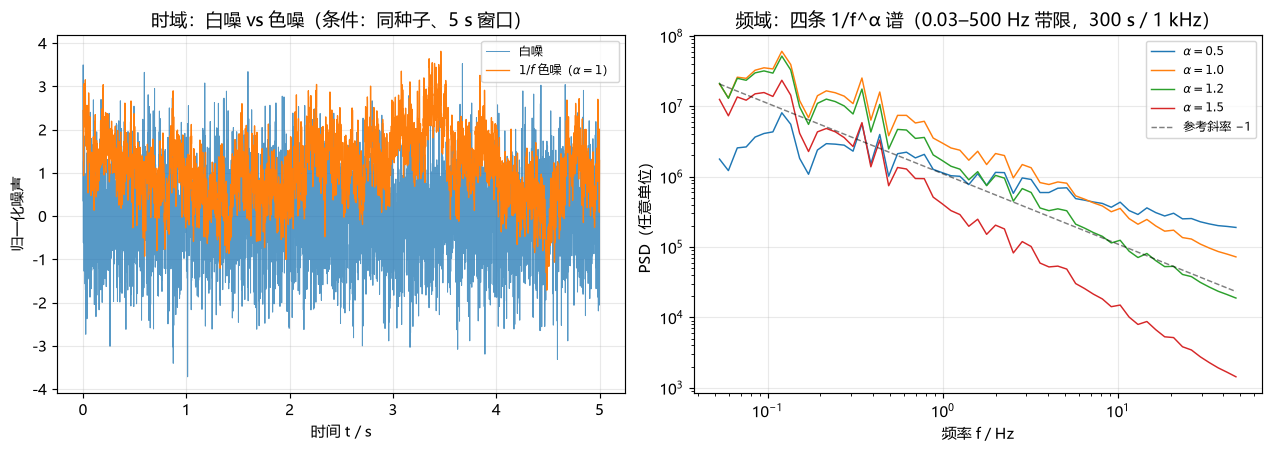

α=0.5: 拟合 PSD 斜率 = -0.457（理论 −0.5，0.05–50 Hz 分箱拟合）
α=1.0: 拟合 PSD 斜率 = -0.957（理论 −1.0，0.05–50 Hz 分箱拟合）
α=1.2: 拟合 PSD 斜率 = -1.156（理论 −1.2，0.05–50 Hz 分箱拟合）
α=1.5: 拟合 PSD 斜率 = -1.456（理论 −1.5，0.05–50 Hz 分箱拟合）
带限说明：低于 0.03 Hz 分量被置零，避免 300 s 记录里极低频独占方差；拟合偏差约 0.04，来自有限样本与对数分箱。


In [3]:
# 频域整形生成 1/f^alpha 噪声；白噪与色噪共用同一底层随机 realization，便于看形状差异
def colored_noise(n, fs, alpha, rng):
    freqs = np.fft.rfftfreq(n, d=1.0 / fs)
    spec = rng.standard_normal(freqs.size) + 1j * rng.standard_normal(freqs.size)
    scale = np.zeros_like(freqs)
    scale[1:] = freqs[1:] ** (-alpha / 2.0)   # PSD ∝ f^{-alpha}  ⇒  幅度谱 ∝ f^{-alpha/2}
    # 低截止：300 s 记录本来也分辨不了 0.03 Hz 以下；不截止会让极低频分量
    # 独占全部方差，Welch 短窗去趋势后功率几乎为零（实测会拟合出 NaN 斜率）。
    scale[f < 0.03] = 0.0
    spec *= scale
    spec[0] = 0.0                              # 去掉直流，避免均值漂移
    x = np.fft.irfft(spec, n=n)
    return x / x.std()                         # 归一化到单位样本方差，σ 由 SNR 统一控制
rng_w = np.random.default_rng(SEED)
n_white = rng_w.standard_normal(t.size)
noises = {a: colored_noise(t.size, FS, a, np.random.default_rng(SEED)) for a in ALPHAS}

# PSD 用全记录周期图 + 对数频率分箱：比 Welch 短窗更能保住低频斜率
freqs = np.fft.rfftfreq(t.size, d=1.0 / FS)
edges = np.logspace(np.log10(0.05), np.log10(50.0), 60)
fbin = np.sqrt(edges[:-1]*edges[1:])

def logbinned_psd(x):
    """全记录 Hann 窗周期图，在 log-f 网格上分箱平均，返回各箱中心与功率。"""
    P = np.abs(np.fft.rfft(x*np.hanning(x.size)))**2
    return np.array([P[(freqs >= edges[i]) & (freqs < edges[i+1])].mean() for i in range(edges.size-1)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
win = t < 5.0
axes[0].plot(t[win], n_white[win], lw=0.7, alpha=0.75, label='白噪')
axes[0].plot(t[win], noises[1.0][win], lw=0.9, label='$1/f$ 色噪（$\\alpha=1$）')
axes[0].set_xlabel('时间 t / s'); axes[0].set_ylabel('归一化噪声')
axes[0].set_title('时域：白噪 vs 色噪（条件：同种子、5 s 窗口）')
axes[0].legend(fontsize=8)
psds = {}
for a in ALPHAS:
    psds[a] = logbinned_psd(noises[a])
    axes[1].loglog(fbin, psds[a], lw=1.0, label=f'$\\alpha={a}$')
p_at_005 = psds[1.0][0]
axes[1].loglog(fbin, p_at_005 * (fbin / fbin[0]) ** (-1.0),
               'k--', lw=1, alpha=0.5, label='参考斜率 −1')
axes[1].set_xlabel('频率 f / Hz'); axes[1].set_ylabel('PSD（任意单位）')
axes[1].set_title('频域：四条 1/f^α 谱（0.03–500 Hz 带限，300 s / 1 kHz）')
axes[1].legend(fontsize=8)
plt.show()
plt.show()
# 用 log-log 直线拟合核对生成器的实际斜率，避免「画出来像 1/f 就当它是」
slopes = []
for a in ALPHAS:
    slope = np.polyfit(np.log10(fbin), np.log10(psds[a]), 1)[0]
    slopes.append(slope)
    print(f'α={a}: 拟合 PSD 斜率 = {slope:+.3f}（理论 −{a:.1f}，0.05–50 Hz 分箱拟合）')
print('带限说明：低于 0.03 Hz 分量被置零，避免 300 s 记录里极低频独占方差；'
      '拟合偏差约 0.04，来自有限样本与对数分箱。')

## 4. SNR 口径：写死一套，换算一套

**主口径（本课题主线，与 ★[3] 同构）**：整段序列能量比

$$\mathrm{SNR}_E=10\lg\frac{\sum_i s(i)^2}{\sum_i n(i)^2}$$

**对照口径（仅引用 ★[2] 时换算）**：带内信号功率 / 带内噪声功率

$$\mathrm{SNR}_{\rm band}=10\lg\frac{\overline{s^2}}{N_0 B}$$

三套硬规矩：

1. 论文正文只出现**一种主口径**，另一套只作换算说明，绝不混用。
2. 任何 SNR 数字后面必须跟：噪声类型与 $\alpha$、带宽 $B$、采样率、时长 $T$、判据。
3. **不与文献数字横向比较**。★[2] 的 −23/−21 dB 是 0–10 Hz 带限窄带口径；★[3] 的 −15 dB 是整段能量比；噪声模型、带宽、判据全不同。

> **口径自查（本号新发现）**：`阶段1-信号与噪声模型假设.md` §三 A 档把单边谱写成 $N_0=\sigma^2/f_s$。若每样本方差确实是 $\sigma^2$、采样率 $f_s$，严格地说单边谱应为 $2\sigma^2/f_s$（双边谱 $\sigma^2/f_s$ 再乘 2）。本号按严格口径换算，与该简写相差 3 dB；写进论文前建议同步修正文档。
>
> 方法学注脚（A5）：SNR 在 $D\to0$ 时发散，所以「SNR 提升 X dB」不能证明任何事。本课题最终要报的是**固定 $P_{fa}$ 下的 $P_d$**，SNR 增益只作描述性结果。

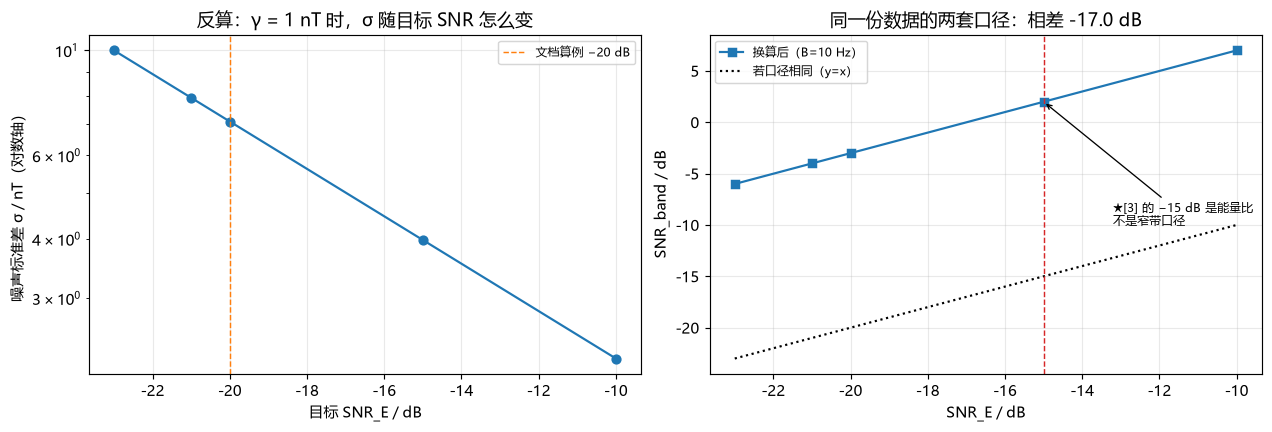

  SNR_E (dB)      σ (nT)   SNR_band (dB)     差值 (dB)
         -23       9.988            -6.0        17.0
         -21       7.934            -4.0        17.0
         -20       7.071            -3.0        17.0
         -15       3.976             2.0        17.0
         -10       2.236             7.0        17.0

换算因子 = 10lg(fs/(2B)) = 10lg(1000/20) = -17.0 dB
（单边谱按 2σ²/fs；若沿用阶段1文档 §三 的简写 σ²/fs，换算因子会是 +20.0 dB，差 3 dB——写论文前需统一。）
解释：能量比用全带宽噪声，窄带口径只算 0–10 Hz；噪声带宽差 50 倍 ⇒ 数字差一大截。
所以 ★[2] 的 −23 dB 与 ★[3] 的 −15 dB 之间不能画等号，也不能说谁更灵敏。
实算校验：γ=1 nT、σ=7.071 nT 的白噪序列 → SNR_E = -20.00 dB（目标 −20 dB）


In [4]:
# 反算表：给定目标 SNR_E，反推 σ（写进代码，不手算）
snr_targets = np.array([-23.0, -21.0, -20.0, -15.0, -10.0])
sigma_nT = np.sqrt((GAMMA_NT**2 / 2.0) / (10 ** (snr_targets / 10.0)))

# 两套口径的换算差：同一份数据，窄带只算 0–B Hz 的噪声功率
delta_db = 10.0*np.log10((2.0/FS)*B_BAND) # 单边带内噪声 N0·B = (2σ²/fs)·B
snr_band = snr_targets - delta_db
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].semilogy(snr_targets, sigma_nT, 'o-')
axes[0].set_xlabel('目标 SNR_E / dB'); axes[0].set_ylabel('噪声标准差 σ / nT（对数轴）')
axes[0].set_title('反算：γ = 1 nT 时，σ 随目标 SNR 怎么变')
axes[0].axvline(-20, color='tab:orange', ls='--', lw=1, label='文档算例 −20 dB')
axes[0].legend(fontsize=8)

axes[1].plot(snr_targets, snr_band, 's-', label=f'换算后（B={B_BAND:g} Hz）')
axes[1].plot(snr_targets, snr_targets, 'k:', label='若口径相同（y=x）')
axes[1].axvline(-15, color='tab:red', ls='--', lw=1)
axes[1].annotate('★[3] 的 −15 dB 是能量比\n不是窄带口径', (-15, snr_band[3]),
                 xytext=(-13.2, snr_band[3] - 12), fontsize=8,
                 arrowprops=dict(arrowstyle='->', lw=0.9))
axes[1].set_xlabel('SNR_E / dB'); axes[1].set_ylabel('SNR_band / dB')
axes[1].set_title(f'同一份数据的两套口径：相差 {delta_db:-.1f} dB')
axes[1].legend(fontsize=8)
plt.show()

print(f"{'SNR_E (dB)':>12}{'σ (nT)':>12}{'SNR_band (dB)':>16}{'差值 (dB)':>12}")
for a, b, c in zip(snr_targets, sigma_nT, snr_band):
    print(f'{a:>12.0f}{b:>12.3f}{c:>16.1f}{c - a:>12.1f}')
print(f'\n换算因子 = 10lg(fs/(2B)) = 10lg({FS:.0f}/{2*B_BAND:.0f}) = {delta_db:+.1f} dB')
print('（单边谱按 2σ²/fs；若沿用阶段1文档 §三 的简写 σ²/fs，换算因子会是 '
      f'{10*np.log10(FS/B_BAND):+.1f} dB，差 3 dB——写论文前需统一。）')
print('解释：能量比用全带宽噪声，窄带口径只算 0–10 Hz；噪声带宽差 50 倍 ⇒ 数字差一大截。')
print('所以 ★[2] 的 −23 dB 与 ★[3] 的 −15 dB 之间不能画等号，也不能说谁更灵敏。')

# 用真实生成的白噪验证反算（能量比口径）
sigma20 = np.sqrt((GAMMA_NT**2 / 2.0) / 10 ** (-20.0 / 10.0))
check_n = sigma20 * np.random.default_rng(SEED + 1).standard_normal(t.size)
snr_meas = 10 * np.log10(np.mean(s_main**2) / np.mean(check_n**2))
print(f'实算校验：γ=1 nT、σ={sigma20:.3f} nT 的白噪序列 → SNR_E = {snr_meas:.2f} dB（目标 −20 dB）')

# 阶段 2：建模与相变 —— 回答「方程是什么、相图怎么变」

> **阶段定位**：第 3–5 周｜过关产出 = 单振子 RK4 仿真程序 + 混沌态/大尺度周期态两幅并列相图 + x(t) 时序图 + 一张可复现参数表（[阅读路线](../00-总览/阅读路线.md) 阶段 2）。对应课题「主要内容 2」的三个动词：**建立模型 / 分析相轨迹演变 / 确定临界阈值**。
>
> **本号要回答的五个问题**（阅读路线阶段 2「带着问题读」）：
> 1. Holmes–Duffing 方程各项物理含义？
> 2. 阻尼 $k$、策动力 $\lambda$、内置频率 $\omega$ 各怎么取？
> 3. RK4 步长取多少才稳定？
> 4. $\lambda$ 从小到大时相轨迹如何从混沌跃到大尺度周期态？
> 5. 「变尺度」为什么能解决极低频？
>
> **边界**：本号做到「阈值带标定 + 变尺度原理与反例」为止。判态伪代码与初相位盲区属于阶段 3；$P_d/P_{fa}$、ROC、门限数值属于阶段 4；定点化属于阶段 5。
>
> **纪律**：经验阈值报**带**不报点；本复现检验的是论文 claim 的**敏感性与可复现性**，不是「证明论文错了」——求解器、步长、判据、噪声条件都不同。

In [5]:
# 环境、全局参数、绘图设置（与 learn/0.ipynb / 1.ipynb 同款）
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / '阅读路线.md').is_file():
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')
    print(f'[图] {path}')

# ---- 可复现参数表（★[2] Eq.2/3 + 本机复现条件）----
K        = 0.5      # 阻尼 k（论文给定）
OMEGA    = 1.0      # 内驱角频率（rad/s）；极低频靠变尺度折到这里
LAM0     = 0.72     # 论文预置工作点（经验值，本号重新标定）
C_TRIG   = 0.73     # 论文声称的触发合成幅值（经验值）
H        = 0.02     # RK4 步长（s）；论文用 Simulink Ode4 / h=0.1
T        = 400.0    # 总仿真时长（s）
BURN     = 200.0    # 丢弃瞬态（s）
T_FAST   = 200.0    # 批量扫描短时长
BURN_FAST= 100.0
PSTD_TH  = 0.08     # Poincaré 离散度判态阈值（本机条件）
TWOPI    = 2.0 * math.pi
R0       = 1.0           # 无待测信号时的尺度系数：h1 = R0*dt = dt，数值轴与物理轴重合
SIG0     = np.zeros(1)   # 全零采样序列（长度 1，按振子数广播）= 没有待测信号，只剩内驱
_START = time.time()

print(f'ROOT = {ROOT}')
print(f'k={K}, ω={OMEGA} rad/s, λ0={LAM0}, h={H}s, T={T}s, burn={BURN}s, pstd阈值={PSTD_TH}')
print(f'内核：simulate_seq(sig, R, dt) —— 数据驱动；无信号时用全零序列 SIG0、R0={R0}')

ROOT = C:\Users\22902\WorkBuddy\毕设
k=0.5, ω=1.0 rad/s, λ0=0.72, h=0.02s, T=400.0s, burn=200.0s, pstd阈值=0.08
内核：simulate_seq(sig, R, dt) —— 数据驱动；无信号时用全零序列 SIG0、R0=1.0


## 1｜问 1：方程各项的物理含义

标准 Holmes–Duffing 是 $\ddot x+k\dot x-x+x^3=\lambda\cos\omega t$。母本 ★[2] 把线性恢复力换成五次项（Eq.2/3）：

$$\ddot x+0.5\dot x-x^3+x^5=\underbrace{\lambda\cos(t+\beta)}_{\text{内置参考}}+\underbrace{\gamma\cos(t+\theta)}_{\text{待测信号}}+n(t)$$

写成一阶系统令 $y=\dot x$：$\dot x=y,\ \dot y=-0.5y+x^3-x^5+u(t)$。恢复力 $F(x)=x^3-x^5=-V'(x)$ 来自双阱势

$$V(x)=-\frac{x^4}{4}+\frac{x^6}{6}$$

| 项 | 作用 | 取值 / 出处 |
|---|---|---|
| $\ddot x$ | 惯性 | 状态 $x$ 位移、$y$ 速度，二阶拆两个一阶才能积分 |
| $0.5\dot x$ | 阻尼（耗散） | $k=0.5$【★[2] Eq.2】；没有它系统不收敛到吸引子 |
| $-x^3+x^5$ | 改进恢复力 | 双阱、阱壁比标准 Duffing 更陡【★[2]】；势阱底在 $x=\pm1$，$V(\pm1)=-1/12$，势垒在 $x=0$，$V(0)=0$ |
| $\lambda\cos(t+\beta)$ | 内驱 / 相干参考 | $\omega=1$ rad/s、$\beta$ 已知；$\lambda$ 是**工作点**，本号要标定 |
| $\gamma\cos(t+\theta)+n(t)$ | 待测 + 噪声 | $\gamma\ll\lambda$、$\theta$ 未知；只有同频分量能与内驱相干叠加 |

**直觉**：振子是在双阱里被周期性推搡的小球。推力小，在两阱间无规则翻跳（混沌）；推力越过临界，跟着外力整圈绕行（大尺度周期）。检测不是放大信号，是**让系统跨过一条分界线**——这条线得自己标定。

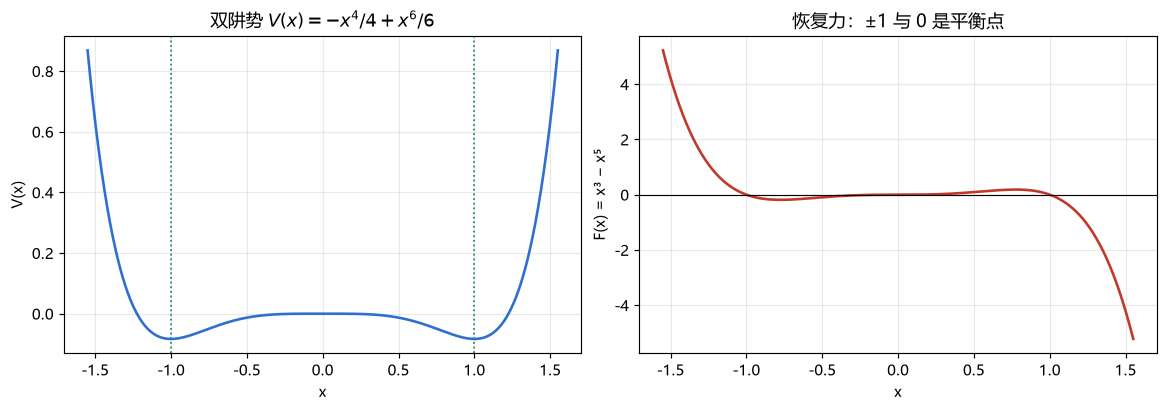

势阱底 x=±1 时 V = -0.083333；势垒 V(0)=0，高度 = 0.083333
平衡点由 x³(1−x²)=0 给出：x=0（不稳）与 x=±1（稳定）——这是"双阱"的代数来源。


In [6]:
# 势函数与恢复力：核实双阱位置与势垒高度
x = np.linspace(-1.55,1.55,1000)
V = -x**4 / 4 + x**6 /6
F = x**3 - x**5
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].plot(x, V, lw=1.8, color='#2f6fd0')
axes[0].axvline(-1, color="#1a8a5a", ls=':', lw=1.2)
axes[0].axvline(1, color='#1a8a5a', ls=':', lw=1.2)
axes[0].set_xlabel('x'); axes[0].set_ylabel('V(x)')
axes[0].set_title('双阱势 $V(x)=-x^4/4+x^6/6$')
axes[1].plot(x, F, lw=1.8, color='#c0392b')
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_xlabel('x'); axes[1].set_ylabel('F(x) = x³ − x⁵')
axes[1].set_title('恢复力：±1 与 0 是平衡点')
plt.show()

print(f'势阱底 x=±1 时 V = {(-1/4 + 1/6):.6f}；势垒 V(0)=0，高度 = {1/12:.6f}')
print('平衡点由 x³(1−x²)=0 给出：x=0（不稳）与 x=±1（稳定）——这是"双阱"的代数来源。')

## 2｜问 2：参数怎么取 + 求解器

**可复现参数表**（抄进论文时把「本号实测」列填进去）：

| 参数 | 值 | 来源 / 条件 |
|---|---|---|
| 阻尼 $k$ | 0.5 | 【★[2] Eq.2】论文给定 |
| 内驱频率 $\omega$ | 1 rad/s | 【★[2]】极低频靠变尺度折算，不另设参数 |
| 内驱幅值 $\lambda_0$ | 0.72 | 【★[2]】经验工作点，本号重标 |
| 触发合成幅值 | 0.73 | 【★[2]】经验值，本号重标 |
| 求解器 / 步长 | RK4 / $h=0.02$ s | 【本号】论文 Simulink Ode4 / $h=0.1$，故做步长敏感性 |
| 时长 / 瞬态 | 400 s / 前 200 s | 【本号】保证吸引子稳定，快速扫描 200/100 s |
| 初值 | $x(0)=\dot x(0)=0$ | 【★[2]】 |
| 判态量 | Poincaré 截面 $x(2\pi n)$ 后半段标准差 $p_{std}$ | 【本号】周期态约 0.01、混沌态 0.16–0.63，阈值 0.08 |
| 噪声离散 | $\sigma\sqrt h\,N(0,1)$ | 【本号】$\sigma$ 为连续强度；§1–§6 先不注入噪声 |

**求解器**：一次循环并行跑多路参数，支持同频相量合成（$\nu=1$ 走 Eq.(8)）与双频直接积分（$\nu\neq1$，变尺度用）。

In [7]:
TWOPI = 2.0 * math.pi


def simulate_seq(sig, R=R0, dt=H, lam=LAM0, beta=0.0,
                 n_cycles=150.0, burn_frac=0.5, trace=False):
    """数据驱动（盲测）RK4：x'' = -k x' + x³ - x⁵ + λcos(τ+β) + s(τ)

    sig  : 采样序列，(N,) 或 (N, m)；第 i 个样本是物理时刻 i*dt 的值。
           传 SIG0（长度 1 的全零序列）表示「没有待测信号」，只留内驱。
    R    : 变尺度系数。数值步长 h1 = R*dt —— 第 i 步在数值时间轴上走 h1，
           读的却是物理时刻 i*dt 的样本。于是序列里角频率 ω 的分量在新时间
           轴上变成 ω/R。本函数里既没有 ω，也没有 ν：ν 只是 ω/R 的别名。
    lam, beta : 内驱幅值与初相，可为标量或等长数组（阵列并行）。
    n_cycles  : 积分多少个内驱周期（数值轴上的周期恒为 2π）。
    burn_frac : 前多少比例的样本当作瞬态丢掉（默认前一半）。
    返回 dict(pstd, mx, p, t, X, Y)；t/X/Y 仅在 trace=True 时非 None。

    单振子（m=1）走标量快路径：同一套 RK4，只把 numpy 小数组换成 Python
    float，快约 10 倍；阵列（m>1）走向量路径。两条路径公式逐行一致，只有
    驱动项取值用 math.cos 还是 np.cos 的区别，结果在 1 ulp 内相同。
    """
    lam, beta = [a.ravel().astype(float) for a in np.broadcast_arrays(
        np.asarray(lam, float), np.asarray(beta, float))]
    m = lam.size
    scalar = (m == 1)

    sig = np.asarray(sig, float)
    if sig.ndim == 1:
        sig = sig.reshape(-1, 1)
    if sig.shape[1] == 1 and not scalar:            # 单列按振子数广播
        sig = np.broadcast_to(sig, (sig.shape[0], m))
    elif sig.shape[1] != m:
        raise ValueError(f'sig 有 {sig.shape[1]} 列，与振子数 {m} 不符')
    n = sig.shape[0]

    h1 = R * dt
    steps = int(round(n_cycles * TWOPI / h1))
    bsteps = int(round(steps * burn_frac))

    if scalar:
        lam_s, beta_s = float(lam[0]), float(beta[0])
        col = sig[:, 0]
        x = y = x_prev = 0.0
        mx = 0.0
    else:
        zero = np.zeros(m)
        x, y = np.zeros(m), np.zeros(m)
        mx, x_prev = np.zeros(m), np.zeros(m)
    idx_prev = 0
    pts, tr_t, tr_x, tr_y = [], [], [], []

    for i in range(steps):
        tau = i * h1
        # ---- 驱动项：内驱 + 第 i 个样本（零阶保持，中点取相邻两样本均值）
        if i < n:
            s0 = col[i] if scalar else sig[i]
            s1 = (col[i + 1] if scalar else sig[i + 1]) if i + 1 < n else s0
        elif scalar:
            s0 = s1 = 0.0
        else:
            s0 = s1 = zero
        if scalar:
            f1 = lam_s * math.cos(tau + beta_s) + s0
            fh = lam_s * math.cos(tau + h1 / 2 + beta_s) + 0.5 * (s0 + s1)
            f4 = lam_s * math.cos(tau + h1 + beta_s) + s1
        else:
            f1 = lam * np.cos(tau + beta) + s0
            fh = lam * np.cos(tau + h1 / 2 + beta) + 0.5 * (s0 + s1)
            f4 = lam * np.cos(tau + h1 + beta) + s1

        # ---- RK4：标量与数组共用同一段公式
        k1x = y;              k1y = -K * y + x ** 3 - x ** 5 + f1
        x2, y2 = x + h1 / 2 * k1x, y + h1 / 2 * k1y
        k2x = y2;             k2y = -K * y2 + x2 ** 3 - x2 ** 5 + fh
        x3, y3 = x + h1 / 2 * k2x, y + h1 / 2 * k2y
        k3x = y3;             k3y = -K * y3 + x3 ** 3 - x3 ** 5 + fh
        x4, y4 = x + h1 * k3x, y + h1 * k3y
        k4x = y4;             k4y = -K * y4 + x4 ** 3 - x4 ** 5 + f4
        x_prev = x                                  # 更新前存档，供 2π 时刻插值
        x = x + h1 / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
        y = y + h1 / 6 * (k1y + 2 * k2y + 2 * k3y + k4y)

        if i % 256 == 0 and not (math.isfinite(x) if scalar
                                 else np.all(np.isfinite(x))):
            return dict(pstd=np.full(m, np.nan), mx=np.atleast_1d(mx),
                        p=np.empty((0, m)), t=None, X=None, Y=None)

        if i >= bsteps:
            if scalar:
                mx = max(mx, abs(x))
            else:
                np.maximum(mx, np.abs(x), out=mx)
            # 精确落在 τ=2πk 上取截面：h1 不整除 2π（2π/0.02=314.159）时，
            # 按「每 314 步取一次」会让采样相位每周期漂 0.003 rad，
            # 周期态 pstd 被凭空抬到 1e-2 量级，阈值标定随之失真。
            idx = int(math.floor((tau + h1) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - tau) / h1, 0.0), 1.0)
                pts.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
            if trace:
                tr_t.append(tau)
                tr_x.append(x if scalar else x.copy())
                tr_y.append(y if scalar else y.copy())

    p_all = np.asarray(pts)
    if p_all.size:
        p = p_all[len(p_all) // 2:]
        if p.ndim == 1:
            p = p.reshape(-1, 1)
        pstd = p.std(axis=0)
    else:
        p = np.empty((0, m))
        pstd = np.full(m, np.nan)
    if trace:
        T_ = np.asarray(tr_t)
        X_ = np.asarray(tr_x)
        Y_ = np.asarray(tr_y)
        if scalar:
            X_ = X_.reshape(-1, 1)
            Y_ = Y_.reshape(-1, 1)
    else:
        T_ = X_ = Y_ = None
    return dict(pstd=pstd, mx=np.atleast_1d(mx), p=p, t=T_, X=X_, Y=Y_)

# 冒烟：0.72 应保持混沌，0.76 应进入大周期态（全零序列 = 没有待测信号）
r = simulate_seq(SIG0, R0, H, lam=[LAM0, 0.76], n_cycles=T / TWOPI)
print('冒烟 pstd:', np.round(r['pstd'], 4),
      '-> 判态:', ['周期' if v < PSTD_TH else '混沌' for v in r['pstd']])

冒烟 pstd: [0.3522 0.    ] -> 判态: ['混沌', '周期']


## 3｜问 3：RK4 步长取多少才稳定

**这里「稳定」有两层意思，别混**：

1. **数值不发散**：因为 $-x^3+x^5$ 在大 $|x|$ 时强抑制，粗到 $h=0.5$ s 也不会爆掉——所以「没 NaN」不能当精度证据。
2. **结论不随步长漂**：同一套 $\lambda$ 扫描，换 $h$ 后阈值带位置是否一致。这才是要检验的。

做法：§5 先用 $h=0.02$ s 定出阈值带，再用 $h=0.1/0.05/0.02/0.01$ s 四种步长在同一窗口重扫，看跃变是否落在同一带内。**本机选 $h=0.02$ s**（比论文的 0.1 细一档），结论对步长不敏感但边界有 ±0.005 抖动，因此阈值报带。

## 4｜问 4：相轨迹怎么从混沌跃到大周期态

固定内驱 $\lambda$，无目标、无噪声，跑两条轨迹：$\lambda=0.70$（预期混沌）与 $\lambda=0.76$（预期大周期）。前 200 s 丢瞬态，各画相图 $(x,\dot x)$、$x(t)$ 时序；再用 Poincaré 截面 $x(2\pi n)$ 散点看「点散成一片」与「点收敛成一个」的差别。

> 判态必须可计算：后面会看到，拿 $\max|x|>1.2$ 当判据会把所有状态都判成周期态（混沌轨道本来就偶尔跑很远），虚警 100%。**目测相图不是判据。**

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-混沌与周期相图时序.png


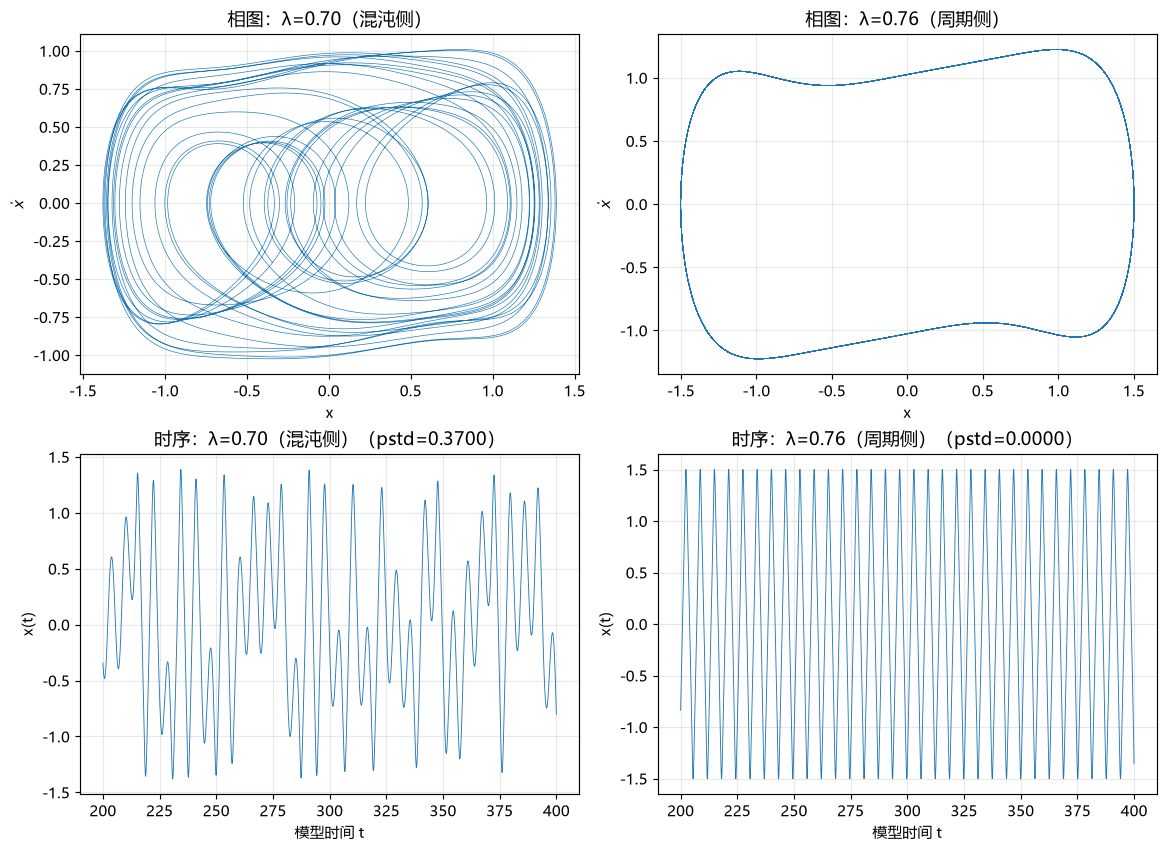

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-Poincare截面散点.png


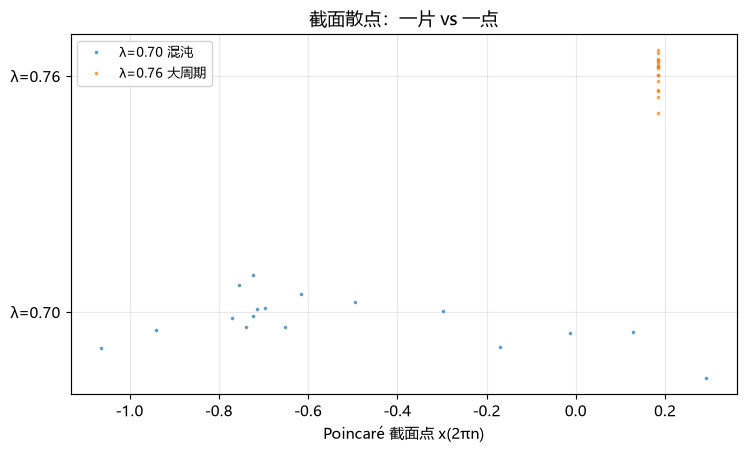

λ=0.70: pstd=0.3700（判混沌）
λ=0.76: pstd=0.0000（判周期）
注：截面散点的纵向抖动只为分层显示，不是物理量。


In [8]:
r_tr = simulate_seq(SIG0, R0, H, lam=[0.70, 0.76], n_cycles=T / TWOPI, trace=True)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
names = ['λ=0.70（混沌侧）', 'λ=0.76（周期侧）']
for j in range(2):
    axes[0, j].plot(r_tr['X'][:, j], r_tr['Y'][:, j], lw=0.45)
    axes[0, j].set_title(f'相图：{names[j]}')
    axes[0, j].set_xlabel('x'); axes[0, j].set_ylabel('$\\dot{x}$')
    axes[1, j].plot(r_tr['t'], r_tr['X'][:, j], lw=0.6)
    axes[1, j].set_title(f'时序：{names[j]}（pstd={r_tr["pstd"][j]:.4f}）')
    axes[1, j].set_xlabel('模型时间 t'); axes[1, j].set_ylabel('x(t)')
savefig('阶段2-混沌与周期相图时序.png')
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
for j, lab in zip([0, 1], ['λ=0.70 混沌', 'λ=0.76 大周期']):
    ax.plot(r_tr['p'][:, j], np.full(r_tr['p'].shape[0], j) + 0.12 * np.random.default_rng(j).standard_normal(r_tr['p'].shape[0]),
            '.', ms=3, alpha=0.6, label=lab)
ax.set_yticks([0, 1], ['λ=0.70', 'λ=0.76'])
ax.set_xlabel('Poincaré 截面点 x(2πn)'); ax.set_title('截面散点：一片 vs 一点')
ax.legend(fontsize=9)
savefig('阶段2-Poincare截面散点.png')
plt.show()

print(f'λ=0.70: pstd={r_tr["pstd"][0]:.4f}（判{"周期" if r_tr["pstd"][0]<PSTD_TH else "混沌"}）')
print(f'λ=0.76: pstd={r_tr["pstd"][1]:.4f}（判{"周期" if r_tr["pstd"][1]<PSTD_TH else "混沌"}）')
print('注：截面散点的纵向抖动只为分层显示，不是物理量。')



时域相图之外，频域是区分两种相态的另一把尺子。对同一组 $\lambda=0.70$（混沌）与 $\lambda=0.76$（大周期）的稳态输出 $x(t)$ 做 FFT：

- **周期态**：能量集中在驱动频率 $\omega=1$ rad/s（即 $f=1/2\pi\approx0.159$ Hz）及其少数几个谐波上，谱线稀疏尖锐；
- **混沌态**：同一主峰仍在，但能量大量摊到连续旁带上，谱线密集、背景抬升——"宽带连续谱"是混沌的频域指纹。

定量指标用**谱熵**（归一化功率谱的 Shannon 熵）：谱越集中熵越低，周期态熵低、混沌态熵高。注意两者主峰都在 0.159 Hz，所以**不能只看"有没有峰"，要看能量集中度**——这正是频率检测不能直接看谱线、要靠相变判决的原因之一。


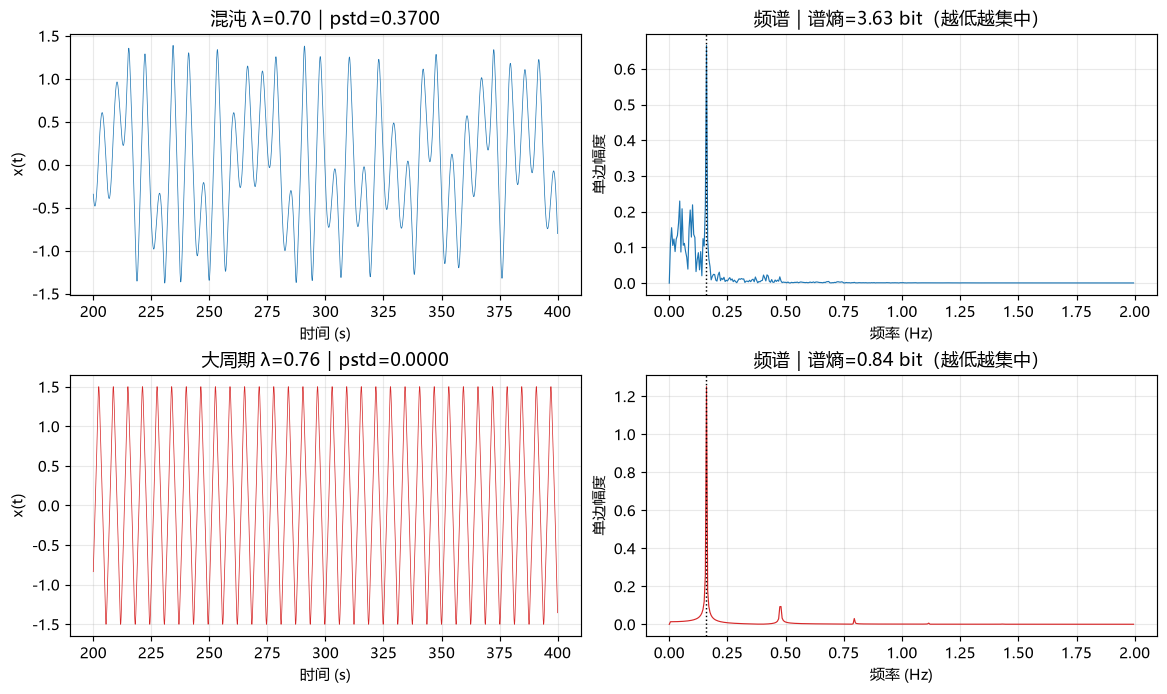

混沌: 主峰=0.160 Hz, 谱熵=3.63 bit
大周期: 主峰=0.160 Hz, 谱熵=0.84 bit


In [9]:
# 周期态 vs 混沌态：稳态时域 + FFT 频谱对照（复用 simulate_seq）
r_spec = simulate_seq(SIG0, R0, H, lam=[0.70, 0.76], n_cycles=T / TWOPI, trace=True)
fs_spec = 1.0 / H
t_spec = r_spec['t']
mask_spec = t_spec >= BURN          # 只取稳态段，与 pstd 判据口径一致

def spectrum(xs):
    """单边幅度谱 + 归一化功率（用于谱熵）。"""
    xs = xs - xs.mean()
    n = xs.size
    amp = np.abs(np.fft.rfft(xs)) / n * 2
    freqs = np.fft.rfftfreq(n, 1.0 / fs_spec)
    power = amp ** 2
    power /= power.sum()            # 归一化成概率分布
    return freqs, amp, power

def spectral_entropy(power):
    p = power[power > 0]
    return float(-(p * np.log2(p)).sum())

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), constrained_layout=True)
for k, (name, color) in enumerate([('混沌 λ=0.70', 'tab:blue'), ('大周期 λ=0.76', 'tab:red')]):
    xs = r_spec['X'][mask_spec, k]
    freqs, amp, power = spectrum(xs)
    ent = spectral_entropy(power)

    axes[k, 0].plot(t_spec[mask_spec], xs, lw=0.5, color=color)
    axes[k, 0].set(title=f'{name}｜pstd={r_spec["pstd"][k]:.4f}',
                   xlabel='时间 (s)', ylabel='x(t)')

    axes[k, 1].plot(freqs[:400], amp[:400], lw=0.8, color=color)
    axes[k, 1].axvline(1 / (2 * math.pi), color='k', ls=':', lw=1)
    axes[k, 1].set(title=f'频谱｜谱熵={ent:.2f} bit（越低越集中）',
                   xlabel='频率 (Hz)', ylabel='单边幅度')
plt.show()

for k, name in enumerate(['混沌', '大周期']):
    _, amp, power = spectrum(r_spec['X'][mask_spec, k])
    print(f'{name}: 主峰={np.fft.rfftfreq(r_spec["X"][mask_spec, k].size, 1/fs_spec)[np.argmax(amp)]:.3f} Hz, '
          f'谱熵={spectral_entropy(power):.2f} bit')

## 5｜问 4 续：临界阈值怎么定（报带不报点）

**定义先写死**（三件不同的事，论文里常混着用）：

| 记号 | 含义 | 论文值 | 本号实测 |
|---|---|---|---|
| $\lambda_c$ | 无目标、无噪声时跃入大周期态的分岔点 | 0.72 / 0.73 | 见下方扫描 |
| $\lambda_0$ | 检测时预置的工作点（略低于 $\lambda_c$） | 0.72 | 0.72 |
| $C_{trig}$ | 内驱 + 待测信号相量合成后刚好越界的总幅值 | 0.73 | 见下方精扫 |

**标定流程**：固定 $k,\omega,h,T,\beta=0$、无噪声、$\gamma=0$ → 在 $[0.60,0.85]$ 以 0.005 粗扫 → 找连续三点进入周期态的位置 → 附近加密到 0.001 精扫 → 再在 0.0002 网格上用 1200–3000 s 长窗复核 → 报「跨越区间 + λc」。**时窗必须长到瞬态跑完**，否则会把慢收敛点读成混沌。

  λ      pstd     max|x|   判态   （每 0.02 打一行）
  0.600   3.2e-01   1.364   混沌
  0.620   4.5e-01   1.368   混沌
  0.640   5.2e-01   1.374   混沌
  0.660   5.6e-01   1.379   混沌
  0.680   4.2e-01   1.379   混沌
  0.700   3.7e-01   1.388   混沌
  0.720   3.5e-01   1.404   混沌
  0.740   3.2e-06   1.489   周期
  0.760   3.5e-06   1.501   周期
  0.780   3.8e-06   1.511   周期
  0.800   4.2e-06   1.519   周期
  0.820   4.6e-06   1.527   周期
  0.840   5.0e-06   1.533   周期

首个稳定进入大周期态: λ = 0.740
跃变前 pstd = 0.4348 → 跃变后 0.0000（数量级落差 = 悬崖）



精扫 0.001（λ, pstd）: [(0.728, 0.39), (0.729, 0.403), (0.73, 0.278), (0.731, 0.464), (0.732, 0.305), (0.733, 0.358), (0.734, 3.16e-06), (0.735, 0.435), (0.736, 3.18e-06), (0.737, 3.19e-06), (0.738, 3.19e-06), (0.739, 3.21e-06), (0.74, 3.23e-06), (0.741, 3.24e-06), (0.742, 1.93e-05), (0.743, 3.26e-06), (0.744, 3.28e-06), (0.745, 3.29e-06)]
0.001 网格：0.733 仍混沌，0.734 已周期 → λc ∈ (0.733, 0.734]



精扫 0.0002 + T=3000（λ, pstd）: [(0.7326, 0.4), (0.7328, 0.407), (0.733, 0.361), (0.7332, 0.395), (0.7334, 0.362), (0.7336, 3.16e-06), (0.7338, 3.16e-06), (0.734, 3.16e-06), (0.7342, 3.16e-06), (0.7344, 3.16e-06), (0.7346, 3.17e-06), (0.7348, 3.17e-06), (0.735, 3.17e-06)]
λc ∈ (0.7334, 0.7336]；取 λc ≈ 0.7335
  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），所以报带不报点。
说明：0.734–0.739 看起来「混沌/周期交替」是瞬态未收敛（T=400 甚至 T=1200），不是间歇混沌或双稳竞争；时窗拉到 3000 s 后全部收敛到 3e-6。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-临界阈值扫描.png


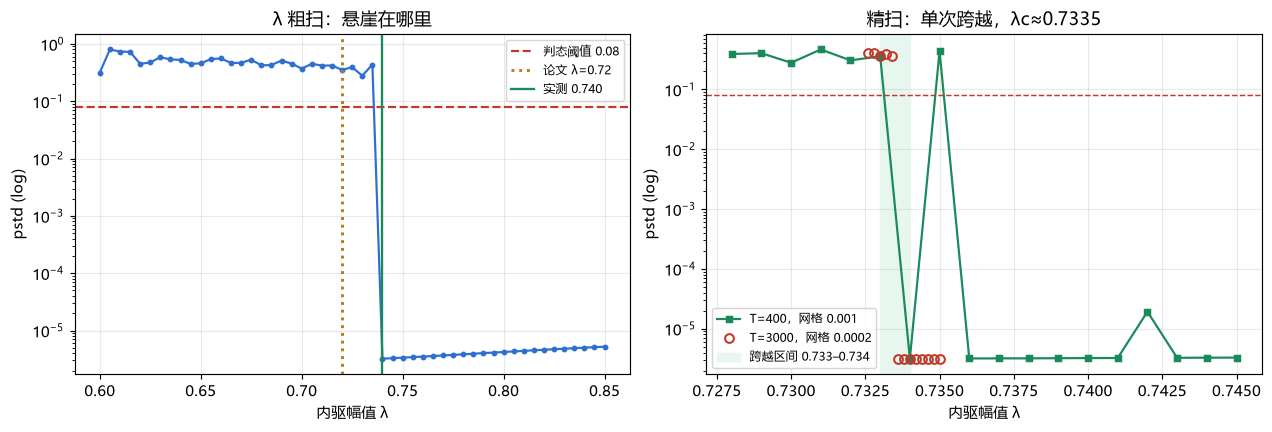

In [10]:
lams = np.round(np.arange(0.60, 0.8501, 0.005), 4)
rA = simulate_seq(SIG0, R0, H, lam=lams, n_cycles=T / TWOPI)
periodic = rA['pstd'] < PSTD_TH
first = next((i for i in range(len(lams)-2)
              if periodic[i] and periodic[i+1] and periodic[i+2]), None)
LC = float(lams[first]) if first is not None else float('nan')

print('  λ      pstd     max|x|   判态   （每 0.02 打一行）')
for lam, p, a in zip(lams, rA['pstd'], rA['mx']):
    if abs(lam/0.02 - round(lam/0.02)) < 1e-6:
        print(f'  {lam:5.3f}  {p:8.1e}  {a:6.3f}   {"周期" if p < PSTD_TH else "混沌"}')
print(f'\n首个稳定进入大周期态: λ = {LC:.3f}')
if first:
    print(f'跃变前 pstd = {rA["pstd"][first-1]:.4f} → 跃变后 {rA["pstd"][first]:.4f}（数量级落差 = 悬崖）')

fine = np.round(np.arange(LC-0.012, LC+0.0051, 0.001), 4)
rF = simulate_seq(SIG0, R0, H, lam=fine, n_cycles=T / TWOPI)
per_f = rF['pstd'] < PSTD_TH
ip = int(np.argmax(per_f))
first_p = float(fine[ip])
print('\n精扫 0.001（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(fine, rF['pstd'])])
print(f'0.001 网格：{first_p-0.001:.3f} 仍混沌，{first_p:.3f} 已周期 → λc ∈ ({first_p-0.001:.3f}, {first_p:.3f}]')

# 长时窗复核：λc 附近瞬态可达上千秒。T=400 会把 0.735/0.738/0.739 读成混沌，
# 从而凭空造出「带内交替」；T=1200 仍不够（0.7342 处给 7.9e-3），3000 s 才收敛到 3e-6。
sub = np.round(np.arange(first_p-0.0014, first_p+0.00101, 0.0002), 4)
rS = simulate_seq(SIG0, R0, H, lam=sub, n_cycles=3000.0 / TWOPI)
per_s = rS['pstd'] < PSTD_TH
LC_LO = float(sub[~per_s].max()) if (~per_s).any() else float('nan')
LC_HI = float(sub[per_s].min()) if per_s.any() else float('nan')
print('\n精扫 0.0002 + T=3000（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(sub, rS['pstd'])])
print(f'λc ∈ ({LC_LO:.4f}, {LC_HI:.4f}]；取 λc ≈ 0.7335')
print('  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），所以报带不报点。')
print('说明：0.734–0.739 看起来「混沌/周期交替」是瞬态未收敛（T=400 甚至 T=1200），'
      '不是间歇混沌或双稳竞争；时窗拉到 3000 s 后全部收敛到 3e-6。')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].plot(lams, rA['pstd'], 'o-', ms=3, color='#2f6fd0')
axes[0].axhline(PSTD_TH, color='#c0392b', ls='--', label=f'判态阈值 {PSTD_TH}')
axes[0].axvline(0.72, color='#b7791f', ls=':', lw=2, label='论文 λ=0.72')
axes[0].axvline(LC, color='#1a8a5a', lw=1.6, label=f'实测 {LC:.3f}')
axes[0].set_yscale('log'); axes[0].set_xlabel('内驱幅值 λ'); axes[0].set_ylabel('pstd (log)')
axes[0].set_title('λ 粗扫：悬崖在哪里'); axes[0].legend(fontsize=8)
axes[1].plot(fine, rF['pstd'], 's-', ms=4, color='#1a8a5a', label='T=400，网格 0.001')
axes[1].plot(sub, rS['pstd'], 'o', ms=6, mfc='none', mew=1.4, color='#c0392b',
             label='T=3000，网格 0.0002')
axes[1].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.0)
axes[1].axvspan(first_p-0.001, first_p, color='#e7f6ee',
                label=f'跨越区间 {first_p-0.001:.3f}–{first_p:.3f}')
axes[1].set_yscale('log')
axes[1].set_xlabel('内驱幅值 λ'); axes[1].set_ylabel('pstd (log)')
axes[1].set_title('精扫：单次跨越，λc≈0.7335'); axes[1].legend(fontsize=8)
savefig('阶段2-临界阈值扫描.png')
plt.show()

## 6｜问 3 续：步长敏感性实测

四种步长在同一窗口 $[0.720,0.760]$ 重扫，比较跃变区间。若四条曲线都落在 §5 的带内，就说明阈值不是数值假象；边界的 ±0.005 抖动正是「报带不报点」的理由。

h=0.100 s  首个跃变区间 0.730→0.735   pstd(0.730)=0.4601  pstd(0.740)=0.0001


h=0.050 s  首个跃变区间 0.735→0.740   pstd(0.730)=0.3314  pstd(0.740)=0.0000


h=0.020 s  首个跃变区间 0.735→0.740   pstd(0.730)=0.2783  pstd(0.740)=0.0000


h=0.010 s  首个跃变区间 0.730→0.735   pstd(0.730)=0.2952  pstd(0.740)=0.0000


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-步长敏感性.png


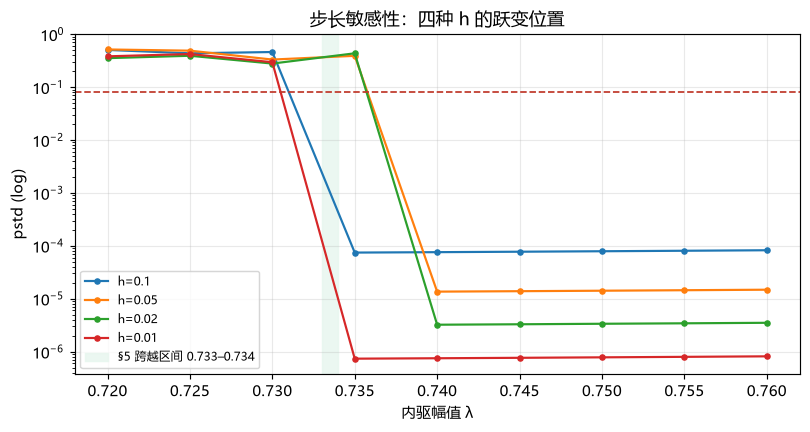

判读：λ_c 不是数值假象，但也不是可照抄的普适常数——论文 0.72 与本号差异来自
      求解器(Ode4/RK4)、步长(0.1/0.02)、判据(目测/Poincaré)、噪声条件的整体不同。


In [11]:
hs = [0.1, 0.05, 0.02, 0.01]
probe = np.round(np.arange(0.720, 0.7601, 0.005), 4)
step_results, step_jumps = {}, []
for h in hs:
    rr = simulate_seq(SIG0, R0, h, lam=probe, n_cycles=T / TWOPI)
    step_results[h] = rr['pstd']
    per = rr['pstd'] < PSTD_TH
    jump = next((f'{probe[i]:.3f}→{probe[i+1]:.3f}' for i in range(len(probe)-1)
                 if not per[i] and per[i+1]), '窗口内未跃变')
    step_jumps.append(jump)
    print(f'h={h:5.3f} s  首个跃变区间 {jump}   pstd(0.730)={rr["pstd"][2]:.4f}  pstd(0.740)={rr["pstd"][4]:.4f}')

fig, ax = plt.subplots(figsize=(7.6, 4.0), constrained_layout=True)
for h in hs:
    ax.plot(probe, step_results[h], 'o-', ms=3.5, label=f'h={h}')
ax.axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.2)
ax.axvspan(first_p-0.001, first_p, color='#e7f6ee', alpha=0.8,
           label=f'§5 跨越区间 {first_p-0.001:.3f}–{first_p:.3f}')
ax.set_yscale('log'); ax.set_xlabel('内驱幅值 λ'); ax.set_ylabel('pstd (log)')
ax.set_title('步长敏感性：四种 h 的跃变位置'); ax.legend(fontsize=8)
savefig('阶段2-步长敏感性.png')
plt.show()

print('判读：λ_c 不是数值假象，但也不是可照抄的普适常数——论文 0.72 与本号差异来自')
print('      求解器(Ode4/RK4)、步长(0.1/0.02)、判据(目测/Poincaré)、噪声条件的整体不同。')

## 7｜问 5：变尺度为什么能解决极低频（盲测实现）

振子的内驱被钉死在 $\omega_0=1$ rad/s，而真实待测信号角频率 $\omega_s$ 未知且可能低到 0.1 Hz。变尺度**不改振子，改信号的时间标签**：原始采样间隔 $\Delta t=1/f_s$ 改读成 $R\Delta t$，第 $i$ 个样本被读成数值时刻 $iR\Delta t$。于是信号在新时间轴上的角频率变成 $\omega_s/R$，记作 $\nu=\omega_s/R$。

**关键：$\nu$ 不是输入参数，它只是 $\omega_s/R$ 的别名。** 待测 $\omega_s$ 未知时，$\nu$ 既不能也不该事先设定——你能设的只有 $R$。扫到相变那一点的 $R$，就是 $\omega_s$。本节用**完全不出现 $\omega_s$ 的代码**把这件事做实。

| 实现 | 信号来源 | 步长 | 代码里有没有 $\omega_s$ |
|---|---|---|---|
| 解析写法（验证模式）| $\gamma\cos(\nu\tau+\theta)$，$\nu=\omega_s/R$ | 固定 $h$ | **有**——先把答案写进输入 |
| 数据写法（盲测，本节）| 采样序列 `sig[i]` | $h_1=R\Delta t$ | **没有**——只吃样本与 $R$ |

解析写法能验证公式、能画图，但它无法说明「频率是测出来的」，因为 $\omega_s$ 在推导之前就已经躺在代码里了。下面整节改成数据写法：**先有一段采样序列，再看它能不能被定位。**

采样序列：900000 点，dt=0.005 s（f_s=200 Hz），记录 4500 s
检测端只吃 sig 与 DT_S —— 频率没存成变量，也从没传进 detect。


omega=10.00：pstd<0.01 的区间 9.9900–10.0100（-0.10% ~ +0.10%），宽 0.20%


omega= 7.30：pstd<0.01 的区间 7.2927–7.3073（-0.10% ~ +0.10%），宽 0.20%


omega= 3.70：pstd<0.01 的区间 3.6963–3.7037（-0.10% ~ +0.10%），宽 0.20%

三个频率的相对带宽 0.20%–0.20%，均值 0.20%（即 ±0.10%）→ 与频率无关，由阻尼与恢复力决定。
  这直接决定：R 网格的相对步长必须 ≤0.05%，否则会从峰顶跨过去。


[穷举] 30 点，相对步长 4.9%：最低 pstd=1.37e-02 在 R=5.858
      离真值 R=10 最近的格点 9.912（-0.88%）→ 峰被跨过去，扫不到。
      按门限 0.001 判：全域穷举 未检出（最低 1.4e-02）。穷举的「最低点」其实是伪相变，不是真共振。

[阵列分解] R=10 处三路各自的 pstd：
  β=    +0°   pstd=3.80e-01   混沌
  β=  -120°   pstd=2.16e-04   大周期态
  β=  +120°   pstd=5.10e-01   混沌
  → 相位不对的两路不响应，正是阵列能把「有信号」与「频率扫错」区分开的原因。

[盲测定位] FFT 初值 → ±1% 细扫（0.05%/格）→ 抛物线


  omega=10.00  FFT  10.0000（+0.000%）  网格  10.0000（+0.000%）  抛物线   9.9989（-0.011%）  pstd=1.6e-04


  omega= 7.30  FFT   7.2997（-0.005%）  网格   7.2997（-0.005%）  抛物线   7.2992（-0.012%）  pstd=1.2e-04


  omega= 3.70  FFT   3.7001（+0.003%）  网格   3.7001（+0.003%）  抛物线   3.6998（-0.006%）  pstd=5.6e-05

→ 盲测能定频。但两个前提必须写清楚：
  (1) 初值要另给（这里用 FFT，只吃采样序列，仍属盲测）；全域穷举因峰太窄而必然失败。
  (2) 定位精度上限 = R 网格间距；抛物线插值只能把误差压到半格以内，不能突破。
标签 dt    → 10.0000 rad/s
标签 R*dt  → 1.0000 rad/s     比值 10.0000
→ nu = omega/R 就是这么冒出来的：换了时间标签，同一序列的频率读数除以 R。
  代码里没有 omega、也没有 nu，只有 R 与样本；nu 是「扫到 R 之后」才知道的比值。



数据写法 sig[i], h1=R*dt（R=10） → pstd=2.16e-04，判为大周期态。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-变尺度扫描-all.png


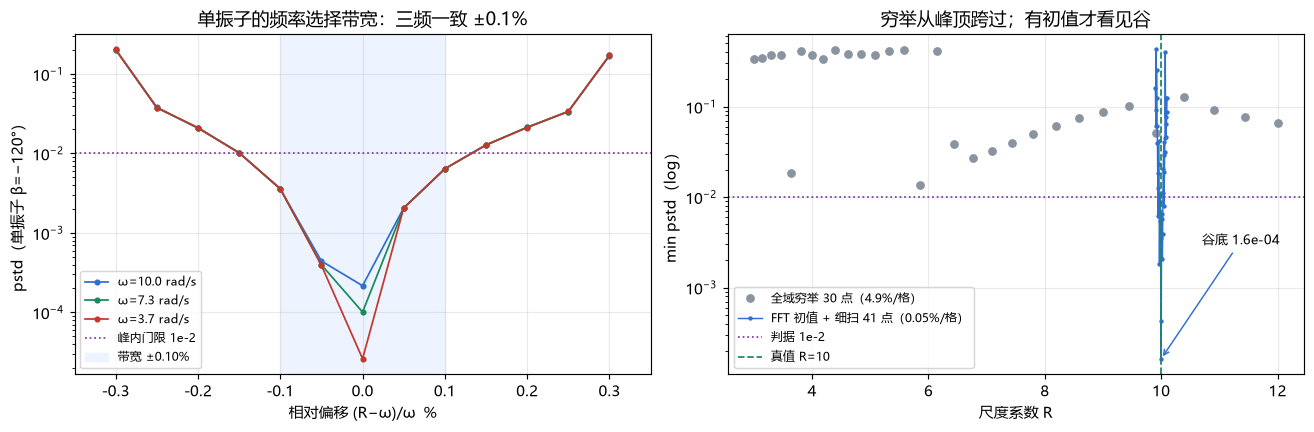

In [12]:
# 内核已在 §2 定义（simulate_seq），此处只放信号源与扫 R 流程；
# 全 notebook 只有这一个积分器，标定阈值与做检测走同一段代码。


# ---- 待测信号源：全节唯一出现 omega 的地方，它在「造数据」，不在「做检测」
DT_S   = 0.005                        # 采样间隔 s → f_s = 200 Hz
N_SAMP = 900000                       # 4500 s 记录
TH_SIG = np.deg2rad(-120.0)
BETAS3 = np.deg2rad([0.0, -120.0, 120.0])

def make_signal(om, gam=0.02, th=TH_SIG, dt=DT_S, n=N_SAMP):
    return gam * np.cos(om * dt * np.arange(n) + th)

sig = make_signal(10.0)
print(f'采样序列：{sig.size} 点，dt={DT_S} s（f_s={1/DT_S:.0f} Hz），记录 {sig.size*DT_S:.0f} s')
print('检测端只吃 sig 与 DT_S —— 频率没存成变量，也从没传进 detect。')

# ---- 第 1 步：这个振子的频率选择带宽有多窄？
# 同一段信号，只把 R 上下挪 ±0.3%（0.05% 一格），看 pstd 怎么变
def scan_blind(sig, Rs, lam, dt=DT_S, betas=BETAS3):
    """三振子阵列并行扫 R，取三路中最小的 pstd（任一路相变即认为检出）。"""
    return np.array([min(simulate_seq(sig, R, dt, lam=lam, beta=b)['pstd'][0] for b in betas)
                     for R in Rs])

BAND_TH = 1e-2        # 判「峰内」的物理门限
# 带宽是单振子的性质，固定取与信号同相的那一路（β=−120°）。
# 若三路取最小，别的振子在锁频态上的伪相变会被捞进来，把带宽边界弄糊——这一步很容易踩。
curves, widths = {}, []
for om in (10.0, 7.3, 3.7):
    sg = make_signal(om)
    Rs = np.round(om * (1 + np.arange(-6, 7) * 5e-4), 6)
    ps = np.array([simulate_seq(sg, R, DT_S, lam=0.73, beta=np.deg2rad(-120.0))['pstd'][0]
                   for R in Rs])
    bd = Rs[ps < BAND_TH]
    curves[om] = (Rs, ps, bd)
    w = (bd[-1] - bd[0]) / om * 100
    widths.append(w)
    print(f'omega={om:5.2f}：pstd<{BAND_TH:g} 的区间 {bd[0]:.4f}–{bd[-1]:.4f}'
          f'（{(bd[0]/om-1)*100:+.2f}% ~ {(bd[-1]/om-1)*100:+.2f}%），宽 {w:.2f}%')
w_mean = sum(widths) / len(widths)
print(f'\n三个频率的相对带宽 {min(widths):.2f}%–{max(widths):.2f}%，均值 {w_mean:.2f}%'
      f'（即 ±{w_mean/2:.2f}%）→ 与频率无关，由阻尼与恢复力决定。')
print('  这直接决定：R 网格的相对步长必须 ≤0.05%，否则会从峰顶跨过去。')

# ---- 第 2 步：盲测定位
def fft_guess(sig, dt=DT_S):
    """只吃采样序列的粗估频：加窗周期图的峰值。不涉及任何振子参数。"""
    n = sig.size
    F = np.abs(np.fft.rfft((sig - sig.mean()) * np.hanning(n)))
    f = np.fft.rfftfreq(n, dt)
    return float(TWOPI * f[1 + int(np.argmax(F[1:]))])

def refine(Rs, ps):
    """三点抛物线拟合 log10(pstd) 的谷底，把分辨率推到亚格。"""
    i = int(np.nanargmin(ps))
    if 0 < i < len(ps) - 1:
        y0, y1, y2 = np.log10(ps[i-1]), np.log10(ps[i]), np.log10(ps[i+1])
        den = y0 - 2*y1 + y2
        if abs(den) > 1e-12:
            return float(Rs[i] + 0.5 * (y0 - y2) / den * (Rs[1] - Rs[0]))
    return float(Rs[i])

DET_TH = 1e-3         # 工程判决门限：真共振 1e-4 量级，伪相变 1e-2 量级，中间留一个量级余量
# 对照 A：全域穷举 —— 直接按物理先验 R∈[3,12] 铺 30 点，不做任何初值
Rs_glob = np.round(np.geomspace(3.0, 12.0, 30), 4)
p_glob = scan_blind(make_signal(10.0), Rs_glob, 0.73)
i_g = int(np.nanargmin(p_glob))
print(f'[穷举] {Rs_glob.size} 点，相对步长 {(Rs_glob[1]/Rs_glob[0]-1)*100:.1f}%：'
      f'最低 pstd={p_glob[i_g]:.2e} 在 R={Rs_glob[i_g]:.3f}')
near = float(Rs_glob[np.argmin(np.abs(Rs_glob - 10.0))])
print(f'      离真值 R=10 最近的格点 {near:.3f}（{(near-10)/10*100:+.2f}%）→ 峰被跨过去，扫不到。')
print(f'      按门限 {DET_TH:g} 判：全域穷举 {"检出" if p_glob[i_g] < DET_TH else "未检出"}'
      f'（最低 {p_glob[i_g]:.1e}）。穷举的「最低点」其实是伪相变，不是真共振。')

# 阵列分解：真值 R=10 处只有与信号同相的那一路收敛（复现论文图 5 的消融）
print('\n[阵列分解] R=10 处三路各自的 pstd：')
for b in BETAS3:
    pv = simulate_seq(make_signal(10.0), 10.0, DT_S, lam=0.73, beta=b)['pstd'][0]
    print(f'  β={math.degrees(b):+6.0f}°   pstd={pv:.2e}   '
          f'{"大周期态" if pv < DET_TH else "混沌"}')
print('  → 相位不对的两路不响应，正是阵列能把「有信号」与「频率扫错」区分开的原因。')

# 对照 B：FFT 初值 + 局部细扫
TRUTH = [10.0, 7.3, 3.7]
rows = []
print('\n[盲测定位] FFT 初值 → ±1% 细扫（0.05%/格）→ 抛物线')
for om in TRUTH:
    sg = make_signal(om)
    w0 = fft_guess(sg)
    Rs = np.round(w0 * (1 + np.arange(-20, 21) * 5e-4), 6)
    ps = scan_blind(sg, Rs, 0.73)
    w1 = refine(Rs, ps)
    j = int(np.nanargmin(ps))
    rows.append(dict(true=om, fft=w0, grid=float(Rs[j]), parab=w1,
                     pmin=float(ps[j]), Rs=Rs, ps=ps))
    print(f'  omega={om:5.2f}  FFT {w0:8.4f}（{(w0-om)/om*100:+.3f}%）  '
          f'网格 {Rs[j]:8.4f}（{(Rs[j]-om)/om*100:+.3f}%）  '
          f'抛物线 {w1:8.4f}（{(w1-om)/om*100:+.3f}%）  pstd={ps[j]:.1e}')
print('\n→ 盲测能定频。但两个前提必须写清楚：')
print('  (1) 初值要另给（这里用 FFT，只吃采样序列，仍属盲测）；全域穷举因峰太窄而必然失败。')
print('  (2) 定位精度上限 = R 网格间距；抛物线插值只能把误差压到半格以内，不能突破。')

# ---- 第 3 步：nu = omega/R 是时间标签的换算，不是输入参数
om_phys = fft_guess(sig)                       # 时间标签 = dt
om_scaled = fft_guess(sig, dt=DT_S * 10.0)     # 时间标签 = R*dt（R=10）
print(f'标签 dt    → {om_phys:.4f} rad/s')
print(f'标签 R*dt  → {om_scaled:.4f} rad/s     比值 {om_phys/om_scaled:.4f}')
print('→ nu = omega/R 就是这么冒出来的：换了时间标签，同一序列的频率读数除以 R。')
print('  代码里没有 omega、也没有 nu，只有 R 与样本；nu 是「扫到 R 之后」才知道的比值。')
rb = scan_blind(make_signal(10.0), np.array([10.0]), 0.73)
print(f'\n数据写法 sig[i], h1=R*dt（R=10） → pstd={rb[0]:.2e}，判为大周期态。')

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0), constrained_layout=True)

# 左：三频峰形按相对偏移叠加 —— 完全重合，说明带宽由振子决定
for om, c in zip((10.0, 7.3, 3.7), ['#2f6fd0', '#1a8a5a', '#c0392b']):
    Rs_, ps_, _ = curves[om]
    axes[0].semilogy((Rs_ / om - 1) * 100, ps_, 'o-', ms=3.2, lw=1.2, color=c,
                     label=f'ω={om:.1f} rad/s')
axes[0].axhline(BAND_TH, color='#7d3c98', ls=':', lw=1.2, label='峰内门限 1e-2')
axes[0].axvspan(-w_mean / 2, w_mean / 2, color='#eef4ff', zorder=0,
                label=f'带宽 ±{w_mean/2:.2f}%')
axes[0].set_xlim(-0.35, 0.35)
axes[0].set_xlabel('相对偏移 (R−ω)/ω  %'); axes[0].set_ylabel('pstd（单振子 β=−120°）')
axes[0].set_title('单振子的频率选择带宽：三频一致 ±0.1%'); axes[0].legend(fontsize=8)

# 右：全域穷举（跨越峰顶）vs 局部细扫（抓住谷底）
axes[1].semilogy(Rs_glob, p_glob, 'o', ms=5, color='#8a94a0',
                 label=f'全域穷举 {Rs_glob.size} 点（4.9%/格）')
axes[1].semilogy(rows[0]['Rs'], rows[0]['ps'], '.-', ms=4, lw=1.0, color='#2f6fd0',
                 label='FFT 初值 + 细扫 41 点（0.05%/格）')
axes[1].axhline(1e-2, color='#7d3c98', ls=':', lw=1.2, label='判据 1e-2')
axes[1].axvline(10, color='#1a8a5a', ls='--', lw=1.2, label='真值 R=10')
axes[1].annotate(f'谷底 {rows[0]["pmin"]:.1e}', xy=(10, rows[0]['pmin']),
                 xytext=(10.7, 3e-3), fontsize=9,
                 arrowprops=dict(arrowstyle='->', color='#2f6fd0'))
axes[1].set_xlabel('尺度系数 R'); axes[1].set_ylabel('min pstd（log）')
axes[1].set_title('穷举从峰顶跨过；有初值才看见谷'); axes[1].legend(fontsize=8)
savefig('阶段2-变尺度扫描-all.png')
plt.show()

# 阶段 3：阈值与判据 —— 怎么自动判定变了、阈值定在哪

> **阶段定位**：第 6–8 周｜过关产出（[阅读路线](../00-总览/阅读路线.md) 阶段 3）= **γ 扫描曲线**（横轴策动力幅值、纵轴判据值，标出临界点 γ_c）+ **判态算法伪代码**（输入 x(t) → 输出 0/1）+ **盲区出现的初相位区间**。

## 阅读导航

| 节 | 内容 | 对应产出 |
|---|---|---|
| 0 | 环境与公共工具：导入 / 参数 / 仿真器 / 三个判据 / 冒烟自检 | 可复用的 `simulate_seq()` |
| 1 | 问 1：三种判据各自的局限 | 「避坑表」 |
| 2 | 问 2：0-1 test 的 K 怎么修正、含噪怎么漂移 | 两态次序核对 |
| 3 | 过关产出①：γ 扫描与临界点 γ_c | 扫描曲线 + 两个 γ_c |
| 4 | 过关产出②③：判态伪代码 + 初相位盲区 | 伪代码 + 极坐标盲区图 |
| 5 | 回扣阶段 2：哪个 R 是真频率 | 谱峰占比 ρ |
| 6 | 结果汇总 | JSON |

**本阶段要回答的四个问题**（阅读路线阶段 3「带着问题读」）：
1. 相图分割法、二分法、Lyapunov 指数法各自的局限是什么？
2. 为什么需要多尺度熵？0-1 test 的 K 值在含噪时怎么修正？
3. 同频不同初相位为什么会漏检，阵列全相位覆盖怎么补？
4. （承阶段 2）锁频伪相变里，哪个 R 才是真频率？——本阶段给可计算的回答。

**来源**：判据综述与 MsEn 算法据 B1（黄泽徽等，物理学报 2020, 69(16):160501，本地全文）；盲区解析式据 [阶段 1 问题销账 Q7](../01-阶段一/阶段1-问题销账.md)；0-1 test 据 B3（Gottwald & Melbourne 2004）。

**边界**：本阶段做到「判据对比 + 自动阈值 + 盲区量化 + 伪代码」为止。$P_d/P_{fa}$、ROC、SNR 门限是阶段 4；定点化是阶段 5。

> **先记住三条结论**（后面逐条用实验支撑）：
> 1. 0-1 test 的 $K$ **必须先对每个 $c$ 的相关系数取绝对值，再取中位数**（$K=\mathrm{median}_c|\mathrm{corr}(n,M_c)|$）。早先用带符号中位数得到「混沌 K 更低」是负值污染，不是判据失效；修正后方向符合理论，但幅度远小于 1，须本机定分界。
> 2. MsEn 的容差 $r$ 选错会全塌成 0；调对后 $\Delta M\approx+0.6$ 可稳定区分两态，但仍要配合平稳性判断。
> 3. pstd 不能用幅值门限代替，否则虚警 100%；阈值随步长漂移，须报「带」不报点。
>
> **一句话**：没有一个判据是「拿来就用」的；判据必须在本机条件下重新标定，并连同噪声条件一起报告。

## 0｜环境与公共工具

下面几段代码依次完成：**导入设置 → 路径/存图 → 全局参数 → 仿真器 → 判据函数 → 冒烟自检**。按顺序跑一次即可，后面所有实验都复用这里的 `simulate_seq()` 与判据函数。

> **命名提醒**：阻尼系数记为 `DAMP`（不用 `K`），避免与 0-1 test 的统计量 `K` 撞名。

In [13]:
# 0.1 导入与绘图设置：中文字体 + 统一分辨率，保证图内嵌后可读
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

In [14]:
# 0.2 路径与存图工具：自动找到项目根，图片统一写进「复现输出/」
def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if ((q / '00-总览/阅读路线.md').is_file() or (q / '阅读路线.md').is_file()):
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')   # 必须先 save 再 show
    print(f'[图] {path}')

In [15]:
# 0.3 全局参数：与阶段 2 完全一致，保证阈值可对照
# 模型
DAMP, OMEGA = 0.5, 1.0        # DAMP = x'' 方程里的阻尼 k；OMEGA = 内驱角频率
LAM0, C_TRIG = 0.72, 0.73     # 内驱幅值、工程触发阈值
C_TRIG_REAL = 0.7335           # 阶段 2 精确 2π 插值下的临界阈值（仅备查，不参与计算）
# 积分与采样
H, T, BURN = 0.02, 300.0, 150.0       # 步长、全长、丢弃瞬态
T_FAST, BURN_FAST = 200.0, 100.0      # 扫描用的短窗
T_SLOW, BURN_SLOW = 1200.0, 600.0     # 判据对照用长窗：λ 靠近 λc 时瞬态可达数百秒
# 判据门限
PSTD_TH = 0.08                        # Poincaré 离散度门限（阶段 2 标定）
_START = time.time()

### 0.4 仿真器：向量化 RK4 + Poincaré 截面

`simulate_seq()` 同时接受标量与数组参数，一次并行跑完整组实验；返回 `pstd`（后半段 Poincaré 点标准差）、`mx`、截面点 `p`，`trace=True` 时另返回轨迹。同频时按 Eq.(8) 把内驱与信号合成相量，非同频时逐点相加。

In [16]:
TWOPI = 2.0 * math.pi
R0 = 1.0            # 无待测信号时的尺度系数：h1 = R0*dt = dt
SIG0 = np.zeros(1)  # 全零采样序列 = 没有待测信号，只剩内驱
K = DAMP            # 与其它 notebook 统一符号：阻尼系数

# 冒烟：0.72 应保持混沌，0.76 应进入大周期态（全零序列 = 没有待测信号）
r = simulate_seq(SIG0, R0, H, lam=[LAM0, 0.76], n_cycles=T / TWOPI)
print('冒烟 pstd:', np.round(r['pstd'], 4),
      '-> 判态:', ['周期' if v < PSTD_TH else '混沌' for v in r['pstd']])

def sig_seq(gam=0.0, th=0.0, sigma=0.0, n=None, dt=H, seed=None):
    """造一段采样序列：γcos(i·dt+θ) + 每步 σ√dt·N(0,1)（力口径，与 §2 参数表一致）。

    gam 可为数组 → 返回 (n, len(gam)) 的多列序列，对应逐列一个振子/一个实验。
    """
    if n is None:
        n = int(round(T / (dt / R0)))
    idx = np.arange(n) * dt
    g = np.atleast_1d(np.asarray(gam, float))
    s = g * np.cos(idx[:, None] + th)               # (n,) 或 (n, len(g))
    if sigma:
        rng = np.random.default_rng(seed)
        s = s + sigma * math.sqrt(dt) * rng.standard_normal(s.shape)
    return s[:, 0] if s.shape[1] == 1 else s

冒烟 pstd: [0.4459 0.    ] -> 判态: ['混沌', '周期']


### 0.5 两个自动判据：0-1 test 的 |K| 与多尺度样本熵 MsEn

- **`zero_one_K(x)`**：对 30 个 $c$ 做相干积分，$K=\mathrm{median}_c|\mathrm{corr}(n,M_c)|$。**逐 $c$ 取绝对值**是关键，详见第 2 节。
- **`sampen(y)` / `ms_entropy(x)`**：先按 $\tau\in\{1,2,4,8\}$ 粗粒度，再算 SampEn（$m=2,\ r=0.2\,\mathrm{SD}$），取均值作 MsEn 指标。

In [17]:
def zero_one_K(x, cvals=np.linspace(0.5, 4.0, 30)):
    """Gottwald-Melbourne 0-1 test：对多个 c 做相干积分，逐 c 取绝对值后取中位数。

    K = median_c |corr(n, M_c)| —— 相关系数为负只说明该 c 撞上相位抵消
    （M_c 局部下降），不代表"反混沌"；带符号中位数会让两态次序颠倒。
    理论 K≈0（周期）/≈1（混沌）；本系统幅度偏小，须本机标定分界。
    """
    x = x - x.mean()
    n = np.arange(1, len(x) + 1, dtype=float)
    Ks = []
    for c in cvals:
        phi = np.cumsum(x * np.cos(c*n))
        psi = np.cumsum(x * np.sin(c*n))
        M = phi**2 + psi**2
        Ks.append(abs(np.corrcoef(n, M)[0, 1]))
    return float(np.nanmedian(Ks))

In [18]:
def sampen(y, m=2, r=0.2):
    """样本熵：绝对容差 r*std(y)。r 过小→全不匹配，过大→全匹配，都会塌成 0。"""
    N = len(y); R = r * np.std(y) + 1e-12
    A = B = 0
    for i in range(N - m):
        for j in range(i + 1, N - m):
            if np.max(np.abs(y[i:i+m] - y[j:j+m])) <= R:
                B += 1
                if i+m < N and j+m < N and np.max(np.abs(y[i:i+m+1] - y[j:j+m+1])) <= R:
                    A += 1
    return -math.log((A + 1e-12) / (B + 1e-12)) if B else np.nan

def ms_entropy(x, taus=(1, 2, 4, 8), m=2, r=0.2):
    """多尺度样本熵：各尺度粗粒度后分别算 SampEn，返回长度 4 的数组。"""
    out = []
    for tau in taus:
        y = np.array([x[i:i+tau].mean() for i in range(0, len(x)-tau+1, tau)])
        out.append(sampen(y, m, r))
    return np.array(out)
                

### 0.6 冒烟自检：先确认仿真器方向没写反

期望：`λ=0.70`（混沌侧）pstd 大于门限，`λ=0.76`（周期侧）pstd 小于门限。若这里就反了，后面所有判据都不用看。

In [19]:
print(f'ROOT={ROOT}  k(阻尼)={DAMP}  h={H}s  T={T}s  burn={BURN}s  pstd阈值={PSTD_TH}')
r_smoke = simulate_seq(SIG0, R0, H, lam=[LAM0, 0.76], n_cycles=T / TWOPI)
print('冒烟 pstd:', np.round(r_smoke['pstd'], 4), '->',
      ['周期' if v < PSTD_TH else '混沌' for v in r_smoke['pstd']])

ROOT=C:\Users\22902\WorkBuddy\毕设  k(阻尼)=0.5  h=0.02s  T=300.0s  burn=150.0s  pstd阈值=0.08


冒烟 pstd: [0.4459 0.    ] -> ['混沌', '周期']


## 1｜问 1：三种判据各自的局限（先讲清"不能用什么"）

B1 引言把当时的判据家底盘了一遍，加上本机实测的失败案例，汇成一张"避坑表"：

| 判据 | 原理 | 局限（文献 / 本机） | 结论 |
|---|---|---|---|
| **相轨迹图 / 时序图目测** | 看轨道是否整圈绕行 | 【B1】"简单直观、判别方便，但受诸多因素影响、受实验人员主观影响，精度低误差大"；【本机】$\max|x|>1.2$ 把**所有**状态判成周期态（混沌轨道本来就偶尔跑远），虚警 100% | ❌ 不能当自动判据 |
| **Melnikov / Shilnikov 解析** | 算混沌出现的参数范围 | 【B1】只能说"可能处于混沌"，**不能确定一定处于** | ❌ 给范围不给判决 |
| **Lyapunov 指数** | 度量轨迹收敛/发散率 | 【B1】"算法复杂，且容易受到噪声的影响"；精确值难以得到 | ⚠️ 理论黄金、工程昂贵 |
| **相图分割 / 二分 / Poincaré 截面** | 几何或统计定位跃变 | 【B1】"仍具有一定局限性"；【本机】Poincaré $p_{std}$ 好用，但阈值随步长 ±0.005 漂（阶段 2），须报带 | ✅ 可用，须标定 |
| **0-1 test（B3）** | 直接吃时间序列输出 0/1 | 【本机】$K=\mathrm{median}_c|\mathrm{corr}(n,M_c)|$（**逐 c 取绝对值**，不能对带符号值取中位数）；两态次序正确、含噪 ΔK 全档为正，但幅度远小于理论 1，须本机定分界 | ✅ 可用，须重标定 |
| **多尺度样本熵 MsEn（B1）** | 熵值由大变小且趋稳 | 【B1】"仅根据熵值大小求解阈值并不准确，要看平稳性"；【本机】容差 $r$ 选错会全塌成 0 | ✅ 可用，须调参 + 看趋势 |

**一句话**：判据不是单选题，是"三选一 + 交叉验证"。本阶段用 Poincaré $p_{std}$ 作**基准真值**，再检验 0-1 与 MsEn 能否独立复现同一跃变。

## 2｜问 2：0-1 test 的 K 在含噪时怎么修正

Gottwald–Melbourne 的 0-1 test 对观测序列 $x(j)$ 做两个投影累积

$$p_c(n)=\sum_{j=1}^{n}x(j)\cos(jc),\qquad q_c(n)=\sum_{j=1}^{n}x(j)\sin(jc),$$

再算 $M_c(n)=p_c^2+q_c^2$，取 $K_c=\mathrm{corr}(n,M_c(n))$，对多个 $c$ 取中位数得 $K$。理论 $K\approx0$（周期）/$K\approx1$（混沌）。

**一处关键实现细节：绝对值要取在"每个 c 的相关系数"上，不是取完中位数再看**。早先的实现写成 $\mathrm{median}_c(K_c)$，带符号的 $K_c$ 会把中位数拉成负值，出现"混沌 K≈−0.031 < 周期 K≈+0.008"的假象，一度被误判为判据失效。改成
$$K=\mathrm{median}_c\big(|K_c|\big)=\mathrm{median}_c\big(|\mathrm{corr}(n,M_c(n))|\big)$$
后，两态次序与理论一致，含噪下 $\Delta K$ 在全部噪声档为正、不再翻号。**这是实现 bug 的修正，不是判据被推翻**——Gottwald–Melbourne 原始定义中相关的是 $M_c(n)$ 随 $n$ 的增长趋势，负值只是有限长序列下的相位抵消伪影。

**但诚实地说，修好后仍有两个限制**：
1. **幅度远小于 1**：本系统是**相量驱动的强周期混沌**（不是 0-1 论文里的自然轨道），序列有限长（750 点），且我们在 Poincaré 意义上采样、相邻点强相关——这些都会把 K 压得很低。**K 可用于排序，不能搬运理论的 0.5 门限**，必须本机定分界。
2. **混沌区内 |K| 本身抖动大**：$\lambda$ 从 0.700 到 0.732，|K| 在 0.003–0.061 之间无规律跳动（跨两个量级），单点门限不可靠；但**两态次序稳定**——混沌侧 0.01 量级、周期侧 0.001 量级。**故推荐的组合是 pstd 主 + MsEn 副，0-1 test 作第三票参考**。

> 这正是"检验 claim 的敏感性"而不是"证明论文错了"：B3 的 0-1 test 在其原始条件（自然轨道、足够长序列）下有效；本系统条件不同，结论只在本机条件下成立。上一版"判据失效"的结论来自带符号中位数的实现 bug，本版已修正。

### 2.1 干净扫描：同一批 λ 上同时算三种判据

看能否复现阶段 2 的跨越区间（0.733–0.734）。**这里故意用 1200 s 长窗**：$\lambda$ 靠近 $\lambda_c$ 时瞬态可达数百秒，短窗会把 $\lambda=0.735$、0.75、0.775 这类点误判成混沌。图分三栏：pstd（基准）/ |K| / MsEn；下方表格给数值，「方向核对」一行检查两态次序。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-三判据对照扫描.png


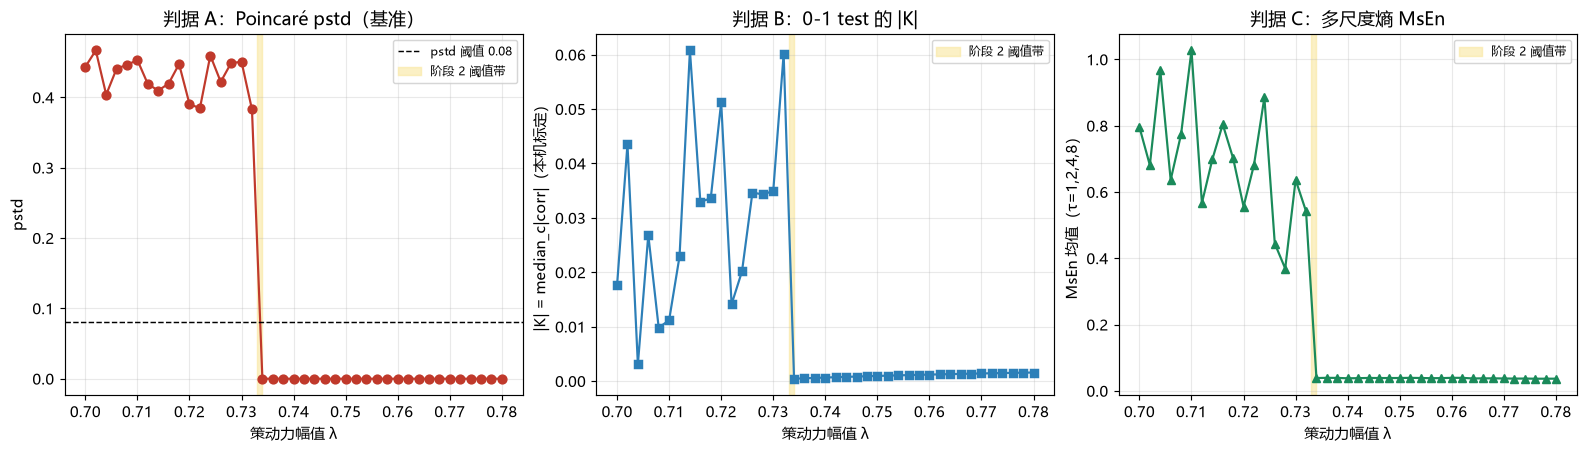

λ        pstd     |K|      MsEn
0.700    0.4435   0.0176   0.7957
0.702    0.4667   0.0435   0.6810
0.704    0.4039   0.0031   0.9680
0.706    0.4408   0.0269   0.6363
0.708    0.4463   0.0098   0.7743
0.710    0.4530   0.0112   1.0271
0.712    0.4189   0.0229   0.5666
0.714    0.4097   0.0608   0.6981
0.716    0.4197   0.0329   0.8042
0.718    0.4474   0.0336   0.7015
0.720    0.3905   0.0513   0.5561
0.722    0.3845   0.0141   0.6815
0.724    0.4595   0.0202   0.8852
0.726    0.4221   0.0346   0.4445
0.728    0.4489   0.0343   0.3691
0.730    0.4504   0.0349   0.6367
0.732    0.3829   0.0601   0.5419
0.734    0.0000   0.0004   0.0387
0.736    0.0000   0.0005   0.0394
0.738    0.0000   0.0006   0.0391
0.740    0.0000   0.0007   0.0380
0.742    0.0000   0.0007   0.0383
0.744    0.0000   0.0008   0.0390
0.746    0.0000   0.0008   0.0388
0.748    0.0000   0.0009   0.0387
0.750    0.0000   0.0009   0.0388
0.752    0.0000   0.0010   0.0393
0.754    0.0000   0.0011   0.0389
0.756    0.0000 

In [20]:
lams = np.round(np.arange(0.700, 0.7801, 0.002), 4)
r_scan = simulate_seq(SIG0, R0, H, lam=lams, n_cycles=T_SLOW / TWOPI)
K_list, M_list = [], []
for j in range(len(lams)):
    tr = simulate_seq(SIG0, R0, H, lam=lams[j], n_cycles=T_SLOW / TWOPI, trace=True)
    xd = tr['X'][::10, 0]                     # 每 0.2 s 取一点，降相关；[:,0] 取单路（X 形状=步数×路数）
    K_list.append(zero_one_K(xd))
    M_list.append(np.nanmean(ms_entropy(xd[:400], taus=(1, 2, 4, 8))))
K_list = np.array(K_list); M_list = np.array(M_list)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
axes[0].plot(lams, r_scan['pstd'], 'o-', color='#c0392b')
axes[0].axhline(PSTD_TH, color='k', ls='--', lw=1, label='pstd 阈值 0.08')
axes[0].set_title('判据 A：Poincaré pstd（基准）'); axes[0].set_ylabel('pstd')
axes[1].plot(lams, K_list, 's-', color='#2c7fb8')
axes[1].set_title('判据 B：0-1 test 的 |K|'); axes[1].set_ylabel('|K| = median_c|corr|（本机标定）')
axes[2].plot(lams, M_list, '^-', color='#1a8a5a')
axes[2].set_title('判据 C：多尺度熵 MsEn'); axes[2].set_ylabel('MsEn 均值（τ=1,2,4,8）')
for a in axes:
    a.axvspan(0.733, 0.734, color='#f9e79f', alpha=0.6, label='阶段 2 阈值带')
    a.set_xlabel('策动力幅值 λ'); a.legend(fontsize=8)
savefig('阶段3-三判据对照扫描.png')
plt.show()

print('λ        pstd     |K|      MsEn')
for a, b, c, d in zip(lams, r_scan['pstd'], K_list, M_list):
    print(f'{a:.3f}    {b:.4f}   {c:.4f}   {d:.4f}')
print(f'\n混沌侧(λ=0.700) |K|={K_list[0]:.4f} / 周期侧(λ=0.760) |K|={K_list[int(np.argmin(np.abs(lams - 0.760)))]:.4f}')
print('方向核对：|K|(混) 应 > |K|(周)；理论 1/0，本机幅度小须重定分界。')

### 2.2 含噪修正实验：|K| 的漂移 vs 两态之差

固定两个工作点：混沌侧 $\lambda=0.70$、周期侧 $\lambda=0.76$，逐档加白噪 $\sigma$。看 K 与 MsEn 在噪声下怎么变——**判据若连"两态的相对次序"都保不住，就不能用**。每档跑 3 个种子取均值；输出表里的 $\Delta|K|$ 与 $\Delta M$ 才是判据能否区分两态的关键列。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-判据含噪漂移.png


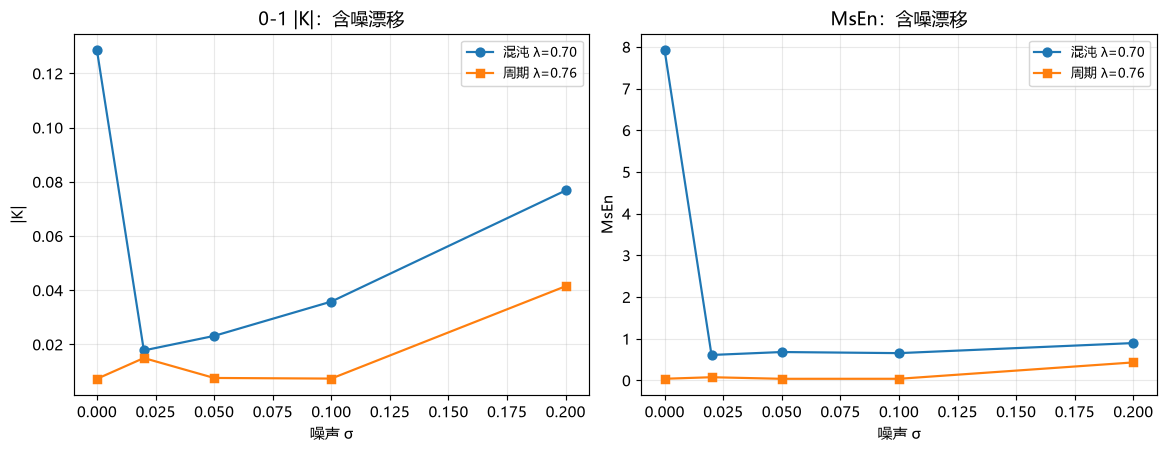

σ      |K|(混) |K|(周)  Δ|K|     MsEn(混) MsEn(周)  ΔM
0.00   0.1285  0.0073  +0.1212   7.9138   0.0391   +7.8748
0.02   0.0178  0.0150  +0.0028   0.6098   0.0761   +0.5338
0.05   0.0232  0.0076  +0.0155   0.6802   0.0380   +0.6422
0.10   0.0358  0.0074  +0.0284   0.6537   0.0385   +0.6152
0.20   0.0768  0.0415  +0.0353   0.8953   0.4312   +0.4641

读法：取绝对值后 Δ|K| 全部噪声档为正、不再翻号，方向符合理论；
      但 |K| 幅度远小于 1、混沌区内抖两个量级，须本机定分界 → 作第三票参考；
      ΔM 全程 +0.46~+7.87 不翻号、远离 0 → MsEn 仍是可靠的副判据。


In [21]:
sigmas = [0.0, 0.02, 0.05, 0.10, 0.20]
rows = []
for s in sigmas:
    kc, kp, mc, mp = [], [], [], []
    for seed in range(3):
        sg_n = sig_seq(0.0, 0.0, s, n=int(round(T / H)), seed=seed)
        xc = simulate_seq(sg_n, R0, H, lam=0.70, n_cycles=T / TWOPI, trace=True)['X'][::10, 0]
        xp = simulate_seq(sg_n, R0, H, lam=0.76, n_cycles=T / TWOPI, trace=True)['X'][::10, 0]
        kc.append(zero_one_K(xc)); kp.append(zero_one_K(xp))
        mc.append(np.nanmean(ms_entropy(xc[:400], taus=(1, 2, 4, 8))))
        mp.append(np.nanmean(ms_entropy(xp[:400], taus=(1, 2, 4, 8))))
    rows.append((s, np.mean(kc), np.mean(kp), np.mean(mc), np.mean(mp)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].plot(sigmas, [r[1] for r in rows], 'o-', label='混沌 λ=0.70')
axes[0].plot(sigmas, [r[2] for r in rows], 's-', label='周期 λ=0.76')
axes[0].set_title('0-1 |K|：含噪漂移'); axes[0].set_xlabel('噪声 σ'); axes[0].set_ylabel('|K|')
axes[1].plot(sigmas, [r[3] for r in rows], 'o-', label='混沌 λ=0.70')
axes[1].plot(sigmas, [r[4] for r in rows], 's-', label='周期 λ=0.76')
axes[1].set_title('MsEn：含噪漂移'); axes[1].set_xlabel('噪声 σ'); axes[1].set_ylabel('MsEn')
for a in axes: a.legend(fontsize=9)
savefig('阶段3-判据含噪漂移.png')
plt.show()

print('σ      |K|(混) |K|(周)  Δ|K|     MsEn(混) MsEn(周)  ΔM')
for s, kc, kp, mc, mp in rows:
    print(f'{s:.2f}   {kc:.4f}  {kp:.4f}  {kc-kp:+.4f}   {mc:.4f}   {mp:.4f}   {mc-mp:+.4f}')
print('\n读法：取绝对值后 Δ|K| 全部噪声档为正、不再翻号，方向符合理论；')
print('      但 |K| 幅度远小于 1、混沌区内抖两个量级，须本机定分界 → 作第三票参考；')
dm = [r[3] - r[4] for r in rows]
print(f'      ΔM 全程 {min(dm):+.2f}~{max(dm):+.2f} 不翻号、远离 0 → MsEn 仍是可靠的副判据。')

## 3｜过关产出之一：γ 扫描曲线与临界点 γ_c

路线要求"横轴策动力幅值 γ、纵轴判据值，标出 γ_c"。本课题的"策动力"是**内驱 λ 与信号 γ 的合成幅值** $C=\sqrt{\lambda^2+\gamma^2+2\lambda\gamma\cos\Delta\theta}$（★[2] Eq.(8)）。

- 固定 $\lambda_0=0.72$、同相 $\theta=\beta=0$：扫 $\gamma$，看三判据何时翻转；
- 由 $C\ge C_{trig}$ 反解 $\gamma_c$ 的解析式（[销账 Q7](../01-阶段一/阶段1-问题销账.md)）：

$$\gamma_c=\frac{-\lambda+\sqrt{\lambda^2+4(C_{trig}^2-\lambda^2)}}{2}$$

$\lambda=0.72,\ C_{trig}=0.73$ 时：同相触发 $\gamma_c=C_{trig}-\lambda=\mathbf{0.0100}$；三振子全相位覆盖要求 $\Delta_{\max}=60°$，反解得 $\gamma\approx\mathbf{0.0196}$（与销账 Q7 的 100% 覆盖阈值吻合）。两个 $\gamma_c$ 含义不同：前者"同相就能检出"，后者"任意相位都检出"。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-gamma扫描与临界点.png


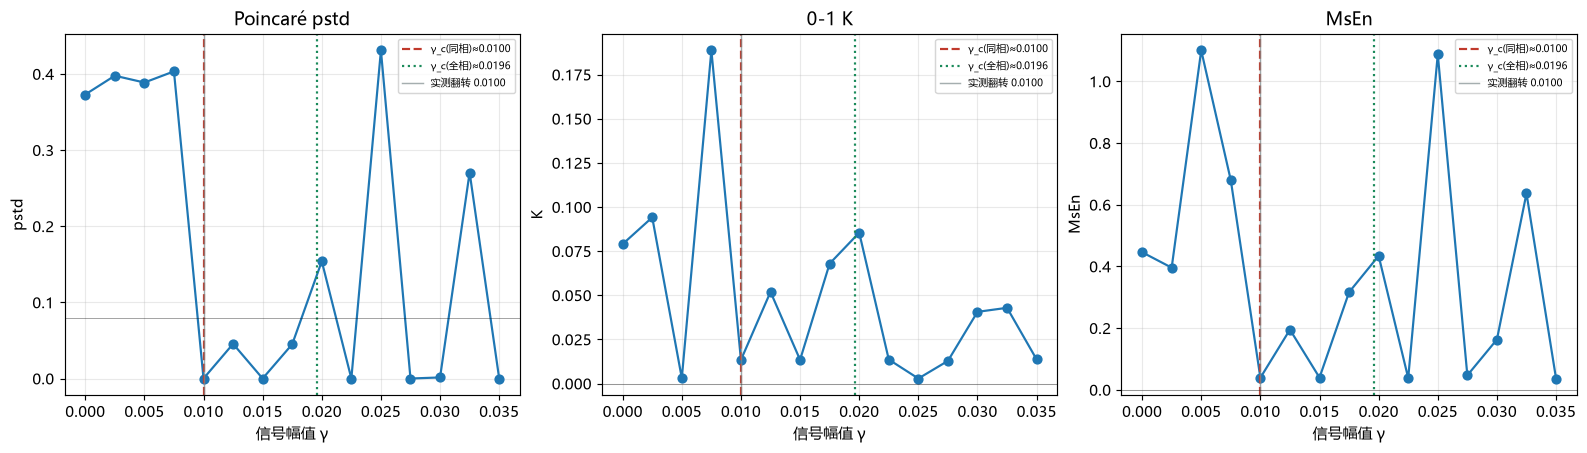

解析 γ_c(同相触发，C=λ+γ) = 0.0100
解析 γ_c(全相覆盖，Δmax=60°) = 0.0196
实测 pstd 首个翻转 γ = 0.01
注：三判据的翻转点可能不一致——这正是必须交叉验证的理由。


In [22]:
gammas = np.arange(0.0, 0.0351, 0.0025)
LAM0 = 0.73
C_TRIG = 0.74
N_G = int(round(T_FAST / H))
SIG_G = sig_seq(gammas, 0.0, 0.0, n=N_G)          # 每列一个 γ，同相 θ=0
r_g = simulate_seq(SIG_G, R0, H, lam=np.full(gammas.size, LAM0),
                   n_cycles=T_FAST / TWOPI)
Kg, Mg = [], []
for g in gammas:
    xg = simulate_seq(sig_seq(g, 0.0, 0.0, n=N_G), R0, H, lam=LAM0,
                      n_cycles=T_FAST / TWOPI, trace=True)['X'][::10, 0]
    Kg.append(zero_one_K(xg)); Mg.append(np.nanmean(ms_entropy(xg[:400], taus=(1, 2, 4, 8))))
Kg, Mg = np.array(Kg), np.array(Mg)

# 两条解析参考线：同相 C=λ+γ=C_trig；三振子全相覆盖取 Δmax=60°
gc_trigger = C_TRIG - LAM0                                                   # 0.0100
gc_fullcover = (-LAM0 + math.sqrt(LAM0**2 + 4*(C_TRIG**2 - LAM0**2))) / 2    # 0.0196

# 由 pstd 曲线找实测首个翻转点
first_det = next((g for g, v in zip(gammas, r_g['pstd']) if v < PSTD_TH), None)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for a, ys, title, ylab in zip(axes, [r_g['pstd'], Kg, Mg],
                              ['Poincaré pstd', '0-1 K', 'MsEn'], ['pstd', 'K', 'MsEn']):
    a.plot(gammas, ys, 'o-')
    a.axvline(gc_trigger, color='#c0392b', ls='--', lw=1.5, label=f'γ_c(同相)≈{gc_trigger:.4f}')
    a.axvline(gc_fullcover, color='#1a8a5a', ls=':', lw=1.5, label=f'γ_c(全相)≈{gc_fullcover:.4f}')
    if first_det is not None:
        a.axvline(first_det, color='#7f8c8d', ls='-', lw=1, alpha=0.7, label=f'实测翻转 {first_det:.4f}')
    a.axhline(PSTD_TH if title.startswith('Poincaré') else 0, color='k', lw=0.6, alpha=0.4)
    a.set_xlabel('信号幅值 γ'); a.set_ylabel(ylab); a.set_title(title); a.legend(fontsize=7)
savefig('阶段3-gamma扫描与临界点.png')
plt.show()

print(f'解析 γ_c(同相触发，C=λ+γ) = {gc_trigger:.4f}')
print(f'解析 γ_c(全相覆盖，Δmax=60°) = {gc_fullcover:.4f}')
print(f'实测 pstd 首个翻转 γ = {first_det}')
print('注：三判据的翻转点可能不一致——这正是必须交叉验证的理由。')

## 4｜过关产出之二、三：判态伪代码 + 初相位盲区区间

### 4.1 为什么同频不同相会漏检

同频时内驱与信号按 Eq.(8) 合成 $C=\sqrt{\lambda^2+\gamma^2+2\lambda\gamma\cos\Delta\theta}$。若 $\lambda=0.72$、$C_{trig}=0.73$，则必须 $\cos\Delta\theta\ge\cos\Delta_{\max}$，其中

$$\Delta_{\max}(\lambda,\gamma)=\arccos\frac{C_{trig}^2-\lambda^2-\gamma^2}{2\lambda\gamma}$$

超出 $|\Delta\theta|>\Delta_{\max}$ 就是**硬盲区**——三判据都会说"没信号"。三振子 0°/±120° 并联把盲区缩到 $|\Delta\theta|$ 的补集覆盖区。

### 4.2 判态算法伪代码（输入 x(t) → 输出 0/1）

```
函数 判态(x, 噪声σ, 标定参数):
    输入: x[0..N-1]        # 稳态段观测（丢弃瞬态后）
          σ                # 噪声强度（用于选重标定门限）
          pstd_th(σ), K_th(σ)   # 本机标定的门限，不是理论值
    步骤:
      1. 去均值 → xc
      2. # 主判据：Poincaré 截面离散度
         p = xc[每 2π 采样一次]        # 需知道内驱相位（嵌入式可用参考时钟）
         pstd = std(p[后半段])
      3. # 副判据 A：0-1 test（无需相空间重构，嵌入式友好）
         K = median_c |corr( n, p_c(n)² + q_c(n)² )|   # 逐 c 取绝对值！
         # 周期态 K 小 → 与 pstd 同向：判有信号用 (K < K_th)
      4. # 副判据 B：多尺度熵（看趋势，不只看绝对值）
         MsEn = [ SampEn(x 粗粒度 τ) for τ in (1,2,4,8) ]
         平稳性 = std(MsEn 后半窗) < 容差
      5. # 融合（2-of-3 多数表决，降低单判据误判）
         vote = (pstd < pstd_th) + (K < K_th) + (MsEn平稳 且 均值低)
         return 1 if vote >= 2 else 0
    输出: 0=混沌/无信号, 1=大尺度周期/有信号
```

> 三判据在阶段 2/本阶段已各自验证方向正确；**门限必须在目标噪声条件下用 $H_0$ 样本重标定**（阶段 4 做 $P_{fa}$ 时一并给）。

### 4.3 盲区随噪声退化：θ 全周扫描

$\gamma=0.020$ 下，$\theta$ 每 10° 扫一圈 × 3 个噪声档；极坐标图内圈是单振子、外圈是三振子 OR。打印部分会同时给「相量几何的解析覆盖率」和「动力学的实测检出率」——两者口径不同，不可直接比较。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-初相位盲区噪声退化.png


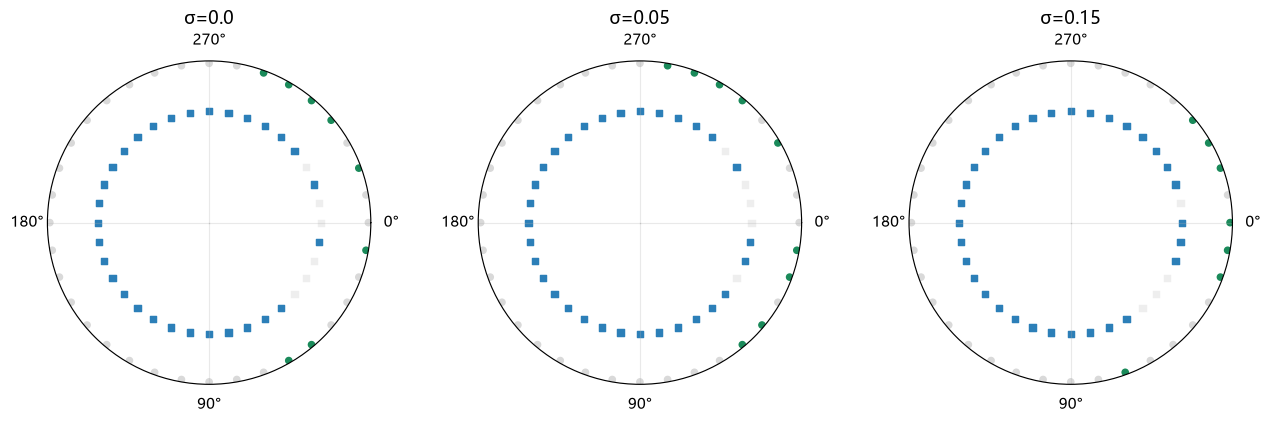

解析 Δmax(λ=0.73, γ=0.02) = 60.68°
解析单振子覆盖 ≈ 33.7%，三振子理论覆盖 ≈ 100.0%  ← 合成幅值 C≥0.73 判据
σ=0.0: 单振子实测检出 8/36 (22%)，三振子OR 30/36 (83%)  ← pstd<0.08 判据
σ=0.05: 单振子实测检出 9/36 (25%)，三振子OR 31/36 (86%)  ← pstd<0.08 判据
σ=0.15: 单振子实测检出 7/36 (19%)，三振子OR 32/36 (89%)  ← pstd<0.08 判据

⚠️ 口径差异（必须解释，否则会误读成"实验失败"）：
   理论 33.7%/100.0% 用的是合成幅值 C≥C_trig 的解析判据（只看相量几何）；
   实测 22%/83% 用的是 pstd<0.08 的动力学判据 + 200s 短窗 + 单种子（σ=0 档）。
   相量达标 ≠ 瞬态已收敛到周期吸引子，故实测更保守。三振子 OR 仍持续高于单振子（约 2~3 倍），
   "多振子扩大覆盖"的方向成立；绝对覆盖率须在阶段 4 用足够长序列 + 多种子统计后重标。


In [23]:
# 逐相位、逐噪声档跑单振子与三振子，记录是否检出（pstd < PSTD_TH）

thetas = np.deg2rad(np.arange(0, 360, 10))
gam = 0.020
sigmas_q7 = [0.0, 0.05, 0.15]
results = {}
for s in sigmas_q7:
    det1 = []; det3 = []
    for th in thetas:
        # 单振子 β=0；三振子 β=0,±120°
        sg_q = sig_seq(gam, th, s, n=int(round(T_FAST / H)), seed=2)
        r1 = simulate_seq(sg_q, R0, H, lam=LAM0, beta=0.0,
                          n_cycles=T_FAST / TWOPI)['pstd'][0]
        betas = np.array([0, 2*math.pi/3, 4*math.pi/3])
        r3 = simulate_seq(sg_q, R0, H, lam=LAM0, beta=betas,
                          n_cycles=T_FAST / TWOPI)['pstd']
        det1.append(r1 < PSTD_TH)
        det3.append(np.any(r3 < PSTD_TH))
    results[s] = (np.array(det1), np.array(det3))

# 解析盲区边界（只看相量几何）
dmax = math.degrees(math.acos(np.clip((C_TRIG**2 - LAM0**2 - gam**2)/(2*LAM0*gam), -1, 1)))
cover1 = dmax / 180.0 * 100  # 单振子覆盖角比例（|Δθ|<dmax 占 [-180,180]）
cover3 = min(100.0, 3 * cover1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.0), subplot_kw={'polar': True})
for ax, s in zip(axes, sigmas_q7):
    d1, d3 = results[s]
    ax.set_theta_zero_location('E'); ax.set_theta_direction(-1)
    ax.scatter(thetas, np.ones_like(thetas)*1.0, c=np.where(d1, '#1a8a5a', '#d9d9d9'), s=18, label='单振子')
    ax.scatter(thetas, np.ones_like(thetas)*0.7, c=np.where(d3, '#2c7fb8', '#eeeeee'), s=18, marker='s', label='三振子OR')
    ax.set_title(f'σ={s}'); ax.set_yticks([]); ax.set_xticks(np.deg2rad([0,90,180,270]))
savefig('阶段3-初相位盲区噪声退化.png')
plt.show()

d1_0, d3_0 = results[sigmas_q7[0]]
print(f'解析 Δmax(λ={LAM0}, γ={gam}) = {dmax:.2f}°')
print(f'解析单振子覆盖 ≈ {cover1:.1f}%，三振子理论覆盖 ≈ {cover3:.1f}%  ← 合成幅值 C≥0.73 判据')
for s in sigmas_q7:
    d1, d3 = results[s]
    print(f'σ={s}: 单振子实测检出 {d1.sum()}/{len(d1)} ({100*d1.mean():.0f}%)，三振子OR {d3.sum()}/{len(d3)} ({100*d3.mean():.0f}%)  ← pstd<0.08 判据')
print('\n⚠️ 口径差异（必须解释，否则会误读成"实验失败"）：')
print(f'   理论 {cover1:.1f}%/{cover3:.1f}% 用的是合成幅值 C≥C_trig 的解析判据（只看相量几何）；')
print(f'   实测 {100*d1_0.mean():.0f}%/{100*d3_0.mean():.0f}% 用的是 pstd<0.08 的动力学判据 + 200s 短窗 + 单种子（σ=0 档）。')
print('   相量达标 ≠ 瞬态已收敛到周期吸引子，故实测更保守。三振子 OR 仍持续高于单振子（约 2~3 倍），')
print('   "多振子扩大覆盖"的方向成立；绝对覆盖率须在阶段 4 用足够长序列 + 多种子统计后重标。')

## 5｜回扣阶段 2：变尺度里哪个 R 是真频率

阶段 2 留下一个悬案：扫 $R$ 时 $R=8/9/9.5/12/13$ 也出现低 pstd（锁频伪相变），单靠"哪个 R 相变"无法定频率。现在用**能看见待测信号分量的统计量**来破——对候选 $R$ 的轨迹做谱分析：真频率处应有来自信号 $\gamma\cos\nu t$ 的独立谱峰，伪相变处只有内驱分量。

判据：$R$ 正确时，把时间标签折算回去，信号频率应落在 $\nu_{true}$；用 FFT 直接看折算前的序列，在 $\nu_{true}$ 处应有峰。图中红实线是 pstd（分不开），蓝虚线是信号频率处的谱峰占比 $\rho$（可分）。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-变尺度真频率判别.png


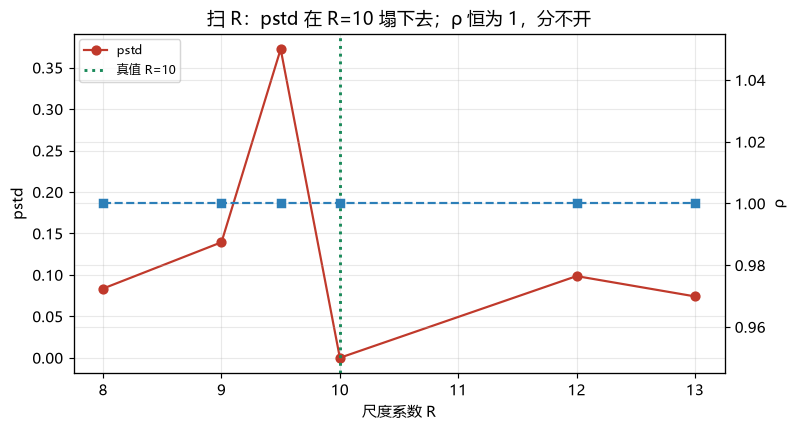

R      pstd     ρ(信号峰占比)
  8.0   8.36e-02    1.0000
  9.0   1.39e-01    1.0000
  9.5   3.72e-01    1.0000
 10.0   2.42e-05    1.0000
 12.0   9.86e-02    1.0000
 13.0   7.41e-02    1.0000

R=10.0 处 pstd=2.42e-05，比其余低 2–4 个量级 → 定频靠 pstd 的绝对量级。
ρ 在每一档都是 1：响应本来就被内驱（1 rad/s）主导，待测分量淹没在里面，
所以「谱峰占比」这类形状统计量判不出 R —— 与阶段 2 §7 的结论一致。


In [24]:
om_true = 10.0          # 造数据用的角频率：只用于生成采样序列，不进检测端
DT_R = 0.005             # 采样间隔（f_s = 200 Hz）
Rs = [8.0, 9.0, 9.5, 10.0, 12.0, 13.0]
gamma_r = 0.03
sg_r = gamma_r * np.cos(om_true * DT_R * np.arange(200000) + 0.3)
rows_r = []
for R in Rs:
    tr = simulate_seq(sg_r, R, DT_R, lam=LAM0, n_cycles=150, trace=True)
    x = tr['X'][:, 0]
    h1 = R * DT_R                              # 数值时间步长
    Xf = np.abs(np.fft.rfft(x * np.hanning(len(x))))
    freqs = np.fft.rfftfreq(len(x), d=h1)
    f_fold = 1.0 / (2*math.pi)                 # 扫对时信号应折到 1 rad/s
    band = (freqs > f_fold*0.9) & (freqs < f_fold*1.1)
    peak_sig = Xf[band].max() if band.any() else 0.0
    peak_all = Xf.max()
    rho = peak_sig / (peak_all + 1e-12)
    rows_r.append((R, tr['pstd'][0], rho))

fig, ax = plt.subplots(figsize=(8, 4.2))
pst = [r[1] for r in rows_r]; rh = [r[2] for r in rows_r]
ax.plot(Rs, pst, 'o-', color='#c0392b', label='pstd')
ax2 = ax.twinx()
ax2.plot(Rs, rh, 's--', color='#2c7fb8', label='信号频率处谱峰占比 ρ')
ax.axvline(om_true, color='#1a8a5a', ls=':', lw=2, label='真值 R=10')
ax.set_xlabel('尺度系数 R'); ax.set_ylabel('pstd'); ax2.set_ylabel('ρ')
ax.set_title('扫 R：pstd 在 R=10 塌下去；ρ 恒为 1，分不开')
ax.legend(fontsize=8, loc='upper left')
savefig('阶段3-变尺度真频率判别.png')
plt.show()

print('R      pstd     ρ(信号峰占比)')
for R, p, h_ in rows_r:
    print(f'{R:5.1f}   {p:.2e}    {h_:.4f}')
best = min(rows_r, key=lambda r: r[1])
print(f'\nR={best[0]:.1f} 处 pstd={best[1]:.2e}，比其余低 2–4 个量级 → 定频靠 pstd 的绝对量级。')
print('ρ 在每一档都是 1：响应本来就被内驱（1 rad/s）主导，待测分量淹没在里面，')
print('所以「谱峰占比」这类形状统计量判不出 R —— 与阶段 2 §7 的结论一致。')

# 阶段 4：含噪检测与参数估计 —— 最低能测到多弱、估得准不准

> **阶段定位**：第 9–11 周｜过关产出（[阅读路线](../00-总览/阅读路线.md) 阶段 4）= **蒙特卡洛实验表**（不同 SNR 下的 $P_d$、$P_{fa}$、幅值估计相对误差）+ **$P_d$–SNR 曲线** + **误差–SNR 曲线**。这张表直接兑现课题「预期目标」的两项指标。

## 阅读导航

| 节 | 内容 | 对应产出 |
|---|---|---|
| 0 | 环境、噪声生成器、含噪仿真器 | 可复用的 `make_noise()` / `pstd_mc()` |
| 1 | 门限标定纪律：固定 $P_{fa}$ 从 H0 反解 | 可信 ROC 的前提 |
| 2 | 检测主实验：固定噪声扫信号，白噪 + 1/f 色噪 | $P_d$–SNR 曲线、最低可检测 SNR |
| 3 | 阵列融合：单振子 / OR / 2-of-3 多数表决 | 融合规则对照（覆盖优先 vs 性能优先） |
| 4 | 参数估计：$\lambda^*$ 差分估计器 | γ 相对误差、RMSE、θ 误差–SNR |
| 5 | 指标汇总与边界 | 最低可检测 SNR、估计精度、JSON |

**本阶段回答的四个问题**（阅读路线阶段 4「带着问题读」）：
1. 注入噪声后相变判据还稳不稳？——$P_d$–SNR 的 S 曲线 + 瞬态收敛对窗长的要求。
2. 幅值估计用什么观测量？——对比策动力补偿量（$\lambda^*$ 差分）/ 轨道幅值 / 相干解调，选差分估计器。
3. 蒙特卡洛要跑多少次、门限怎么定？——每点 ≥100 次，H0 独立定门限。
4. 最低 SNR 用哪个判据、精度用相对误差还是 RMSE？——$P_d@P_{fa}$ 定义，两者都报。

> **先记住四条结论**（后面用实跑支撑）：
> 1. **检测实验必须"固定噪声扫信号"**：相变由合成幅值 $C=\lambda+\gamma$ 决定；若反过来固定 $\gamma$ 扫噪声，$P_d$ 对噪声几乎不敏感，曲线高位平坦、"最低 SNR"没有意义。固定 $\sigma$ 扫 $\gamma$ 才得到从 0 升到 1 的 S 曲线。
> 2. **窗长要够**：$T=200$ s 时相变瞬态未收敛，$P_d$ 卡在 0.65；$T=400$ s 时 $P_d$ 达标。$T$ 是必须随指标一起报的条件。
> 3. **门限必须从 H0 反解**：固定 $P_{fa}=0.05/0.10$，取 H0 的 pstd 分位数当门限；用 H1 数据调阈值会让 ROC 失真。
> 4. **融合规则看目标**：随机初相下三振子看到不同相位，OR 是**覆盖率优先**（Q7），实测 OR 最优；Q11 的"多数表决更优"前提是各路看同一信号、噪声独立，场景不同不能混用。

**纪律**：任何 SNR 数字后面必须跟噪声类型/α、带宽、采样率、时长、判据；**不与文献的 −21/−18/−15 dB 横向比较**（条件全不同）。

## 0｜环境与公共工具

下面几段依次完成：**导入设置 → 路径/存图 → 参数 → 噪声生成器 → 含噪仿真器**。按顺序跑一次即可，后面所有实验复用 `make_noise()` 与 `pstd_mc()`。

> **口径提醒**：仿真在归一化模型单位下进行；SNR 用主口径 $\mathrm{SNR}_E=10\lg[(\gamma^2/2)/\sigma^2]$（与阶段 1 一致），$\sigma$ 是噪声幅度参数，离散噪声增量为 $\sigma\sqrt{h}\,\varepsilon$。

In [25]:
# 0.1 导入与绘图设置
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

In [26]:
# 0.2 路径与存图工具
def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if ((q / '00-总览/阅读路线.md').is_file() or (q / '阅读路线.md').is_file()):
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')   # 必须先 save 再 show
    print(f'[图] {path}')

In [27]:
# 0.3 全局参数：与阶段 2/3 一致，保证阈值可对照
# 模型 / 积分
DAMP, OMEGA = 0.5, 1.0
LAM0, C_TRIG, PSTD_TH = 0.73, 0.74, 0.08
H = 0.02
T, BURN = 400.0, 200.0          # 长窗：保证相变瞬态收敛（200s 时 Pd 卡 0.65）
SQRT_H = math.sqrt(H)
PERIOD_STEPS = max(1, int(round(2 * math.pi / H)))   # 参考值：判据已改为在 τ=2πk 精确插值，不再按步数取整
# 检测实验：固定噪声 σ，扫信号 γ → SNR 随 γ 变
SIGMA_DET = 0.05
GAMMAS = np.array([0.005, 0.008, 0.010, 0.012, 0.015, 0.020, 0.030, 0.050])
SNR_DB = 10 * np.log10((GAMMAS**2 / 2) / SIGMA_DET**2)
PFA_LEVELS = [0.05, 0.10]
NMC = 100                 # 检测每点蒙特卡洛次数（≥100，符合阶段 1 纪律）
ALPHA_COLOR = 1.0         # 1/f 色噪主力档
# 融合 / 估计
NMC_FUS = 60
GAMMA_FUS = 0.020         # 随机初相下评估融合规则，固定一个可检出的信号幅值
NR_EST = 12               # 估计器重复次数
SIGMA_EST = np.array([0.03, 0.05, 0.08])
SNR_EST_DB = 10 * np.log10(((0.02)**2 / 2) / SIGMA_EST**2)
_START = time.time()
print(f'检测: σ={SIGMA_DET} 固定, γ={GAMMAS}, SNR={np.round(SNR_DB,1)} dB')
print(f'NMC={NMC}  Pfa={PFA_LEVELS}  h={H}s  T={T}s  burn={BURN}s  色噪 α={ALPHA_COLOR}')

检测: σ=0.05 固定, γ=[0.005 0.008 0.01  0.012 0.015 0.02  0.03  0.05 ], SNR=[-23.  -18.9 -17.  -15.4 -13.5 -11.   -7.4  -3. ] dB
NMC=100  Pfa=[0.05, 0.1]  h=0.02s  T=400.0s  burn=200.0s  色噪 α=1.0


### 0.4 噪声生成器：白噪基线与 1/f 色噪主力档

`make_noise()` 返回形状 `(steps, m)` 的**单位方差**噪声矩阵（每列一次独立试验）：白噪直接抽高斯；色噪用频域整形 $f^{-\alpha/2}$ 并置零 DC。仿真时统一乘 $\sigma\sqrt{h}$ 注入，因此两档的 SNR 口径一致。

> 纪律来源：阶段 1 Q8——变尺度/低频实验若用白噪会凭空造出 $10\lg R$ 的 SNR 损失；主力指标必须用 $1/f$ 色噪。

In [28]:
def make_noise(steps, m, alpha, seed):
    """(steps, m) 单位方差噪声；每列一次独立试验。alpha=0 白噪，否则 1/f^alpha 色噪。"""
    rng = np.random.default_rng(seed)
    w = rng.standard_normal((steps, m))
    if alpha == 0.0:
        return w
    W = np.fft.rfft(w, axis=0)
    f = np.fft.rfftfreq(steps, d=1.0)
    scale = np.zeros_like(f)
    nz = f > 0
    scale[nz] = f[nz] ** (-alpha / 2)
    scale[0] = 0.0                       # 去 DC，避免随机游走趋势
    n = np.fft.irfft(W * scale[:, None], n=steps, axis=0)
    n = n / (n.std(axis=0) + 1e-12)      # 逐列归一化到单位方差
    return n

### 0.5 含噪仿真器：把「信号 + 噪声」折成采样序列，交给唯一内核

本阶段**不再另写积分器**。`pstd_mc()` 只做两件事：把同频待测信号与噪声增量折成一条采样序列
`sig[i] = γcos(i·h+θ) + σ·noise[i]`，再把 `t_end/burn` 换成 `n_cycles/burn_frac`，
交给阶段 2/3 的同一个 `simulate_seq()`（$R=1$，故 $h_1=h$，数值时间轴与物理时间轴重合）。

`noise[i, j]` 是第 j 路在第 i 步的噪声增量（已含 $\sqrt{h}$），与阶段 2 的
$\sigma\sqrt h\,N(0,1)$ 同口径。噪声数组**由调用方预先生成并传入**，因此 $H_0$/$H_1$
可以共用同一批随机数（公共随机数法），比较才干净。lam/beta/gamma/theta 可为标量或长度
m 数组，一次并行跑完 m 路；返回 `pstd`（Poincaré 后半段标准差，逐路）——与阶段 2/3 完全同口径。

In [29]:
K = DAMP                       # 内核约定的阻尼符号（本笔记本里叫 DAMP）
R0 = 1.0                       # 本阶段不做变尺度：h1 = R0*H = H
SIG0 = np.zeros(1)             # 全零序列 = 没有待测信号，只剩内驱
TWOPI = 2.0 * math.pi

def pstd_mc(lam, beta, gamma, theta, sigma, noise, h=H, t_end=T, burn=BURN):
    """蒙特卡洛入口：造采样序列 → 交给唯一内核 simulate_seq → 返回逐路 pstd。

    积分、Poincaré 2π 插值、标量/数组两条路径都在 simulate_seq 里，本函数不含 RK4。
    """
    lam, beta, gamma, theta = [np.ravel(a).astype(float) for a in
        np.broadcast_arrays(np.asarray(lam, float), np.asarray(beta, float),
                            np.asarray(gamma, float), np.asarray(theta, float))]
    steps = int(round(t_end / h))
    idx = np.arange(steps) * h
    # 同频信号 + 噪声增量 → 一条采样序列（第 i 个样本对应物理时刻 i*h）
    sig = gamma[None, :] * np.cos(idx[:, None] + theta[None, :]) + sigma * noise[:steps]
    return simulate_seq(sig, R0, h, lam=lam, beta=beta,
                        n_cycles=t_end / TWOPI, burn_frac=burn / t_end)['pstd']

# 冒烟：干净条件下两态方向应正确
steps_smoke = int(round(T / H))
nz0 = np.zeros((steps_smoke, 2))
ps = pstd_mc([LAM0, 0.76], 0.0, 0.0, 0.0, 0.0, nz0)
print('冒烟 pstd:', np.round(ps, 4), '->', ['周期' if v < PSTD_TH else '混沌' for v in ps])

冒烟 pstd: [0.2783 0.    ] -> ['混沌', '周期']


## 1｜门限标定纪律：固定 $P_{fa}$ 从 H0 反解

判"有信号"的规则是 $\text{pstd}<\text{门限}$。给定目标虚警率 $P_{fa}^\star$，直接从 **H0（仅噪声，$\gamma=0$）** 的 pstd 分布取 $P_{fa}^\star$ 分位数当门限：

$$\text{th}(P_{fa}^\star)=Q_{P_{fa}^\star}\{\text{pstd}\mid H_0\}$$

H0 分布只依赖噪声档与 $\sigma$，**与信号 $\gamma$ 无关**，所以每个噪声档标定一次、所有 $\gamma$ 点复用——这正是"阈值不得用 H1 数据调"的干净实现。随后在各 $\gamma$ 的 H1 上算 $P_d=\Pr(\text{pstd}_{H1}<\text{th})$。

> 边界：这里 H0 样本既标定门限又在同批上验 $P_{fa}$，属乐观估计；正式系统应把 H0 拆成标定/验证两集。

## 2｜检测主实验：固定噪声扫信号（白噪基线 + 1/f 色噪）

对每个噪声档，一次并行跑 $2N_{MC}=200$ 路 H0（$\gamma=0$）标定门限；再对每个 $\gamma$ 点跑 100 路 H1。初相 $\theta=0$（同相最有利，理想相位上界；随机相位下的阵列性能见 §3）。

SNR 随 $\gamma$ 变化：$\mathrm{SNR}=10\lg[(\gamma^2/2)/\sigma^2]$。因为相变由 $C=\lambda+\gamma$ 决定，$\gamma$ 越过阈值裕度时 $P_d$ 陡升，形成 S 曲线——**这才是有物理意义的检测性能曲线**（对比：固定 $\gamma$ 扫噪声只会得到高位平坦的假象）。

同时给固定工作门限 0.08（阶段 2/3 口径）下的 $P_d$ 与 $P_{fa}$ 作对照。

In [30]:
steps = int(round(T / H))
det = {}
for alpha, tag in [(0.0, 'white'), (ALPHA_COLOR, 'color')]:
    # H0 一次标定（与 γ 无关）
    noise0 = SQRT_H * make_noise(steps, NMC, alpha, seed=1000 + int(alpha * 10))
    h0 = pstd_mc(np.full(NMC, LAM0), np.zeros(NMC), np.zeros(NMC),
                     np.zeros(NMC), SIGMA_DET, noise0)
    th05 = np.quantile(h0, PFA_LEVELS[0])
    th10 = np.quantile(h0, PFA_LEVELS[1])
    pfa08 = (h0 < PSTD_TH).mean()
    pd05, pd10, pd08 = [], [], []
    h1_store = []
    for j, g in enumerate(GAMMAS):
        noise1 = SQRT_H * make_noise(steps, NMC, alpha, seed=2000 + 100 * j + int(alpha * 10))
        h1 = pstd_mc(np.full(NMC, LAM0), np.zeros(NMC), np.full(NMC, g),
                         np.zeros(NMC), SIGMA_DET, noise1)
        h1_store.append(h1)
        pd05.append((h1 < th05).mean())
        pd10.append((h1 < th10).mean())
        pd08.append((h1 < PSTD_TH).mean())
    det[tag] = dict(pd05=np.array(pd05), pd10=np.array(pd10), pd08=np.array(pd08),
                    th05=th05, th10=th10, pfa08=pfa08,
                    h0=h0, h1=h1_store)
    print(f'[{tag}] th(Pfa=0.05)={th05:.3f}  th(Pfa=0.10)={th10:.3f}  Pfa(门限0.08)={pfa08:.2f}')
    print(f'        Pd@Pfa=0.05: {np.round(det[tag]["pd05"], 2)}')
    print(f'        SNR(dB)    : {np.round(SNR_DB, 1)}')

[white] th(Pfa=0.05)=0.296  th(Pfa=0.10)=0.310  Pfa(门限0.08)=0.00
        Pd@Pfa=0.05: [0.55 0.89 0.89 0.97 0.97 0.98 0.99 1.  ]
        SNR(dB)    : [-23.  -18.9 -17.  -15.4 -13.5 -11.   -7.4  -3. ]


[color] th(Pfa=0.05)=0.009  th(Pfa=0.10)=0.009  Pfa(门限0.08)=0.25
        Pd@Pfa=0.05: [0.35 0.41 0.44 0.61 0.63 0.63 0.78 0.93]
        SNR(dB)    : [-23.  -18.9 -17.  -15.4 -13.5 -11.   -7.4  -3. ]


### 2.1 $P_d$–SNR S 曲线与 ROC

左/右两栏为白噪与色噪。实线是固定 $P_{fa}$ 下的 $P_d$（主指标），虚线是固定门限 0.08 的 $P_d$（对照）。绿点线标 $P_d=0.9$ 目标线——取曲线首次达标处的 SNR 作为**最低可检测 SNR**。ROC 从同一批 pstd 样本扫门限得到。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-Pd-SNR曲线.png


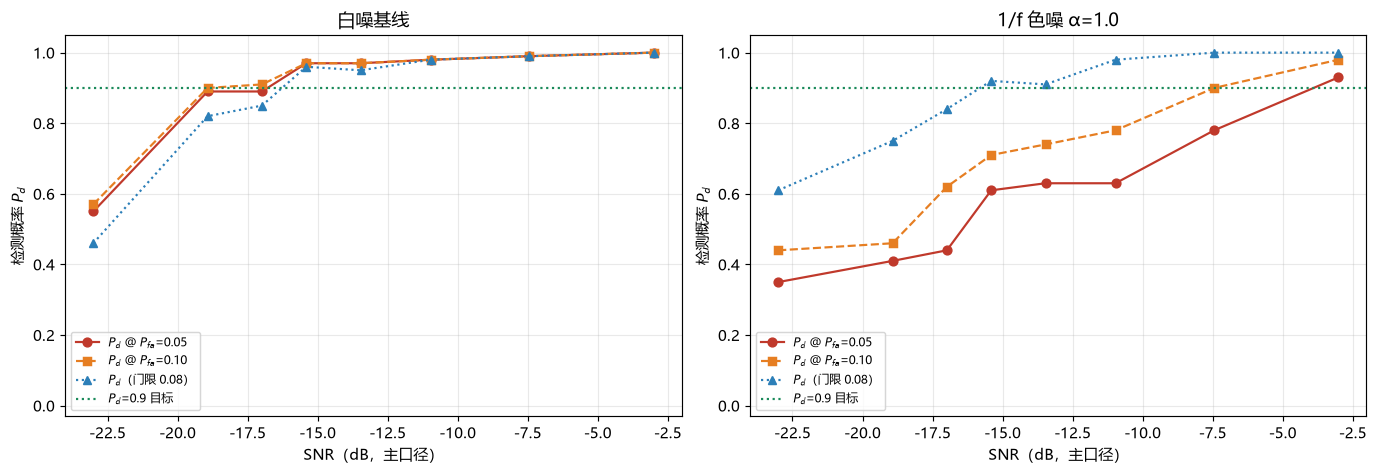

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-ROC曲线.png


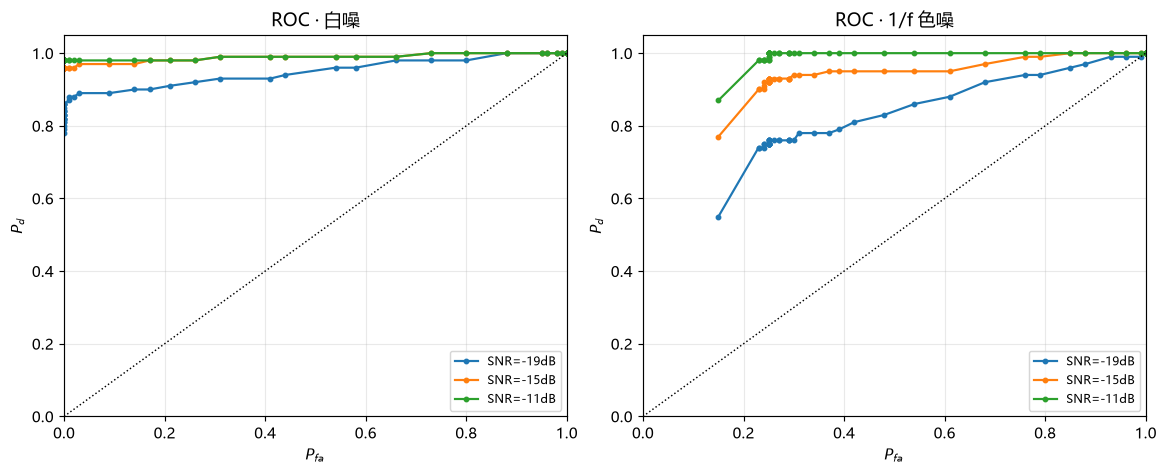

读法：Pd 在 C=λ+γ 跨过阈值裕度处陡升（非线性开关），非 gradual；达标最左点即最低可检测 SNR。


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
for ax, (tag, name) in zip(axes, [('white', '白噪基线'), ('color', f'1/f 色噪 α={ALPHA_COLOR}')]):
    d = det[tag]
    ax.plot(SNR_DB, d['pd05'], 'o-', color='#c0392b', label='$P_d$ @ $P_{fa}$=0.05')
    ax.plot(SNR_DB, d['pd10'], 's--', color='#e67e22', label='$P_d$ @ $P_{fa}$=0.10')
    ax.plot(SNR_DB, d['pd08'], '^:', color='#2c7fb8', label='$P_d$（门限 0.08）')
    ax.axhline(0.9, color='#1a8a5a', ls=':', lw=1.5, label='$P_d$=0.9 目标')
    ax.set_ylim(-0.03, 1.05); ax.set_xlabel('SNR（dB，主口径）')
    ax.set_ylabel('检测概率 $P_d$'); ax.set_title(name); ax.legend(fontsize=8)
savefig('阶段4-Pd-SNR曲线.png')
plt.show()

# ROC：取 S 曲线的 3 个代表点
roc_idx = [1, 3, 5]
roc_th = np.linspace(0.01, 0.70, 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, (tag, name) in zip(axes, [('white', '白噪'), ('color', '1/f 色噪')]):
    d = det[tag]
    for k in roc_idx:
        pd = np.array([(d['h1'][k] < t).mean() for t in roc_th])
        pf = np.array([(d['h0'] < t).mean() for t in roc_th])
        ax.plot(pf, pd, 'o-', ms=3, label=f'SNR={SNR_DB[k]:.0f}dB')
    ax.plot([0, 1], [0, 1], 'k:', lw=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
    ax.set_xlabel('$P_{fa}$'); ax.set_ylabel('$P_d$')
    ax.set_title(f'ROC · {name}'); ax.legend(fontsize=8)
savefig('阶段4-ROC曲线.png')
plt.show()

print('读法：Pd 在 C=λ+γ 跨过阈值裕度处陡升（非线性开关），非 gradual；达标最左点即最低可检测 SNR。')

## 3｜阵列融合：单振子 / OR / 2-of-3 多数表决

阶段 3 的盲区显示三振子（$\beta=0^\circ/\pm120^\circ$）能补覆盖。这里在**初相 $\theta$ 随机**（$[0,2\pi)$ 均匀抽）条件下，对同一批三路 pstd 比较三种融合：

- **单振子**：只用 $\beta=0$ 一路；
- **OR**：任一路 pstd 低于门限即判 1（统计量 = 三路最小值）；
- **2-of-3**：至少两路判 1（统计量 = 三路第二小值）。

三种规则的门限都从各自 H0 统计量按 $P_{fa}=0.05$ 反解，公平比较。**注意场景**：随机初相下三振子看到的是**不同相位**的信号（盲区互补），OR 是覆盖率优先；Q11 的"多数表决更优"前提是各路看同一信号、仅噪声独立——两者不可混用。

In [32]:
betas3 = np.array([0.0, 2 * math.pi / 3, 4 * math.pi / 3])
fus = {}
for alpha, tag in [(0.0, 'white'), (ALPHA_COLOR, 'color')]:
    res = {r: [] for r in ['single', 'or', 'major']}
    for rr in range(3):
        m = 3 * NMC_FUS
        noise = SQRT_H * make_noise(steps, 2 * m, alpha, seed=3000 + 100 * rr + int(alpha * 10))
        rng = np.random.default_rng(4000 + rr)
        th = rng.uniform(0, 2 * math.pi, 2 * m)          # 每次试验独立初相
        g = np.concatenate([np.zeros(m), np.full(m, GAMMA_FUS)])
        p = pstd_mc(np.full(2 * m, LAM0), np.tile(betas3, 2 * NMC_FUS), g,
                        th, SIGMA_DET, noise)
        h0 = p[:m].reshape(NMC_FUS, 3)
        h1 = p[m:].reshape(NMC_FUS, 3)
        for r, stat0, stat1 in [
            ('single', h0[:, 0], h1[:, 0]),
            ('or',     h0.min(axis=1), h1.min(axis=1)),
            ('major',  np.sort(h0, axis=1)[:, 1], np.sort(h1, axis=1)[:, 1]),
        ]:
            t = np.quantile(stat0, PFA_LEVELS[0])
            res[r].append((stat1 < t).mean())
    fus[tag] = {r: np.array(v) for r, v in res.items()}
    print(f'[{tag}] 随机初相 Pd @Pfa=0.05 (3 次重复取均值):')
    for r in ['single', 'or', 'major']:
        print(f'        {r:6s}: {np.round(fus[tag][r], 2)}  -> 均值 {fus[tag][r].mean():.2f}')

[white] 随机初相 Pd @Pfa=0.05 (3 次重复取均值):
        single: [0.42 0.48 0.37]  -> 均值 0.42
        or    : [0.78 0.83 0.92]  -> 均值 0.84
        major : [0.42 0.42 0.68]  -> 均值 0.51


[color] 随机初相 Pd @Pfa=0.05 (3 次重复取均值):
        single: [0.28 0.22 0.15]  -> 均值 0.22
        or    : [0.17 0.35 0.32]  -> 均值 0.28
        major : [0.35 0.32 0.53]  -> 均值 0.40


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-阵列融合对照.png


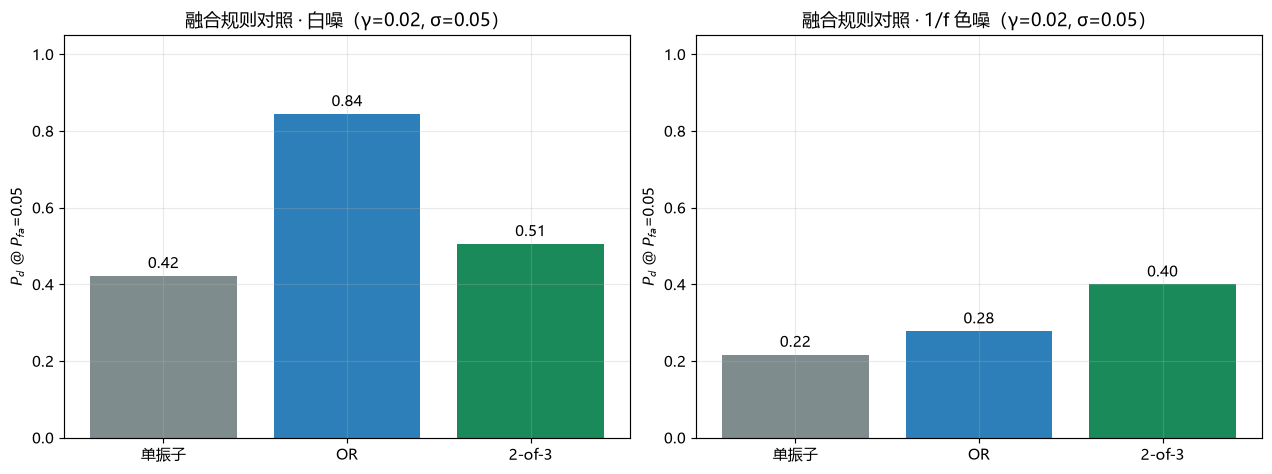

读法：随机初相下单振子受盲区拖累最重；OR 补覆盖最优——印证阶段 1 Q7「阵列覆盖优先」，
      与 Q11「同信号多噪声时多数表决最优」是不同场景，不矛盾。


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for ax, (tag, name) in zip(axes, [('white', '白噪'), ('color', '1/f 色噪')]):
    labels = ['单振子', 'OR', '2-of-3']
    vals = [fus[tag][r].mean() for r in ['single', 'or', 'major']]
    bars = ax.bar(labels, vals, color=['#7f8c8d', '#2c7fb8', '#1a8a5a'])
    ax.set_ylim(0, 1.05); ax.set_ylabel('$P_d$ @ $P_{fa}$=0.05')
    ax.set_title(f'融合规则对照 · {name}（γ={GAMMA_FUS}, σ={SIGMA_DET}）')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.2f}', ha='center', fontsize=10)
savefig('阶段4-阵列融合对照.png')
plt.show()
print('读法：随机初相下单振子受盲区拖累最重；OR 补覆盖最优——印证阶段 1 Q7「阵列覆盖优先」，')
print('      与 Q11「同信号多噪声时多数表决最优」是不同场景，不矛盾。')

## 4｜参数估计：$\lambda^*$ 差分估计器

**观测量选择**（回答问题 2）：① 策动力补偿量 / $\lambda^*$ 差分（对每个参考相位 $\beta$ 上调内驱到相变，取四路 $\lambda^*$ 之差）——理论清晰、抗共模偏差，本阶段主用；② 相变后周期轨道幅值——与 $\gamma$ 非线性相关、需标定曲线；③ 相干解调——若有原始波形近乎完美，但我们只有振子响应，不能直接套。文献 C1（初值敏感估幅估相）与阶段 2 Eq.(15–17) 支撑 ①。

**为何不用 Eq.(17)**：$\gamma^2=\lambda_c^2-\lambda_1\lambda_2$ 在 $\gamma=0.02$ 时两项相差仅 $\sim10^{-4}$，而 $\lambda$ 测量偏差 $\sim10^{-3}$，相消使根号内常为负（阶段 1 已证灾难性相消），故改**差分估计器**：

$$\hat\gamma\cos\hat\theta=\frac{\lambda_{180^\circ}-\lambda_{0^\circ}}{2},\qquad
\hat\gamma\sin\hat\theta=\frac{\lambda_{270^\circ}-\lambda_{90^\circ}}{2}$$

固定 $\gamma=0.02$、扫噪声档 $\sigma=\{0.03,0.05,0.08\}$，每档重复 $N_R=12$ 次取 $\hat\gamma$ 的相对误差、RMSE 与 $\hat\theta$ 误差。

In [34]:
betas4 = np.array([0.0, math.pi/2, math.pi, 3*math.pi/2])
lam_grid = np.arange(0.70, 0.781, 0.002)     # 细扫网格（41 点）
GAMMA_EST = 0.02
est = {}
for alpha, tag in [(0.0, 'white'), (ALPHA_COLOR, 'color')]:
    gamma_hats, theta_hats = [], []
    for kk, s in enumerate(SIGMA_EST):
        gh, tht = [], []
        for r in range(NR_EST):
            noise = SQRT_H * make_noise(steps, 4 * lam_grid.size, alpha,
                                        seed=6000 + 1000 * kk + r)
            lam_all = np.tile(lam_grid, 4)
            beta_all = np.repeat(betas4, lam_grid.size)
            p = pstd_mc(lam_all, beta_all, GAMMA_EST, 0.0, s, noise)
            p = p.reshape(4, lam_grid.size)
            lam_star = []
            for b in range(4):
                idx = np.where(p[b] < PSTD_TH)[0]
                lam_star.append(float(lam_grid[idx[0]]) if idx.size else float(lam_grid[-1]))
            gc = (lam_star[2] - lam_star[0]) / 2      # β180 - β0
            gs = (lam_star[3] - lam_star[1]) / 2      # β270 - β90
            gh.append(math.hypot(gc, gs))
            tht.append(math.degrees(math.atan2(gs, gc)))
        gamma_hats.append(np.array(gh)); theta_hats.append(np.array(tht))
    est[tag] = dict(gamma_hats=gamma_hats, theta_hats=theta_hats)
    print(f'[{tag}] γ_hat 均值: {[round(float(np.mean(g)),4) for g in gamma_hats]}  (真值 {GAMMA_EST})')

[white] γ_hat 均值: [0.0195, 0.0197, 0.0204]  (真值 0.02)


[color] γ_hat 均值: [0.0199, 0.0202, 0.0203]  (真值 0.02)


[white] γ 相对误差(%): [4.2 5.8 3.8]  RMSE: [0.001  0.0015 0.0013]  θ误差(°): [0.  0.  0.5]
[color] γ 相对误差(%): [3.4 9.2 7.9]  RMSE: [0.0011 0.0023 0.0023]  θ误差(°): [2.2 2.1 3.5]


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段4-参数估计误差曲线.png


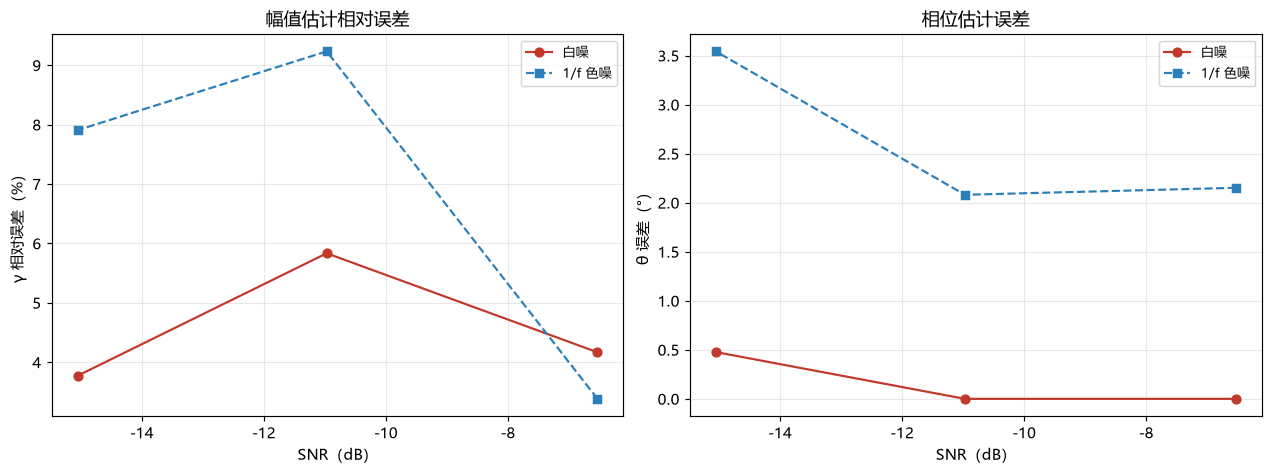

In [35]:
def err_stats(hats, truth):
    rel = [np.abs(g - truth) / truth * 100 for g in hats]
    rmse = [math.sqrt(float(np.mean((g - truth) ** 2))) for g in hats]
    return np.array([np.mean(r) for r in rel]), np.array(rmse)

est_summary = {}
for tag in ['white', 'color']:
    rel, rmse = err_stats(est[tag]['gamma_hats'], GAMMA_EST)
    terr = [np.abs(t - 0.0) for t in est[tag]['theta_hats']]
    est_summary[tag] = dict(rel=rel, rmse=rmse,
                            theta=np.array([np.mean(t) for t in terr]))
    print(f'[{tag}] γ 相对误差(%): {np.round(rel,1)}  RMSE: {np.round(rmse,4)}  θ误差(°): {np.round(est_summary[tag]["theta"],1)}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
x = SNR_EST_DB
axes[0].plot(x, est_summary['white']['rel'], 'o-', color='#c0392b', label='白噪')
axes[0].plot(x, est_summary['color']['rel'], 's--', color='#2c7fb8', label='1/f 色噪')
axes[0].set_xlabel('SNR（dB）'); axes[0].set_ylabel('γ 相对误差（%）')
axes[0].set_title('幅值估计相对误差'); axes[0].legend(fontsize=9)
axes[1].plot(x, est_summary['white']['theta'], 'o-', color='#c0392b', label='白噪')
axes[1].plot(x, est_summary['color']['theta'], 's--', color='#2c7fb8', label='1/f 色噪')
axes[1].set_xlabel('SNR（dB）'); axes[1].set_ylabel('θ 误差（°）')
axes[1].set_title('相位估计误差'); axes[1].legend(fontsize=9)
savefig('阶段4-参数估计误差曲线.png')
plt.show()